# Лабораторная работа № 3
## Генерация графов нормализующим потоком: двухмассовая подвеска Quanser

**Связь с ЛР № 1:** ODE-модель *Mass–Spring–Damper* с двумя степенями свободы (4 переменные состояния).  
**Связь с ЛР № 2:** SMC-оценка распределения параметров → исследование зануления наблюдаемых переменных → статистика Колмогорова–Смирнова → критерий сохранения физических связей.  
**Метод ЛР № 3 (вариант 6):** нормализующий поток RealNVP для генерации графов.

**Реальные данные:** Mohammad Salah (2025), *Quanser Experimental Dataset*, Harvard Dataverse, DOI: [10.7910/DVN/XGTWSJ](https://doi.org/10.7910/DVN/XGTWSJ).

**Второй источник численных данных:** номинальные параметры стенда Quanser из таблицы 1 статьи [*Sliding Mode Control for Active Suspension System with Data Acquisition Delay*](https://doi.org/10.1155/2014/529293).

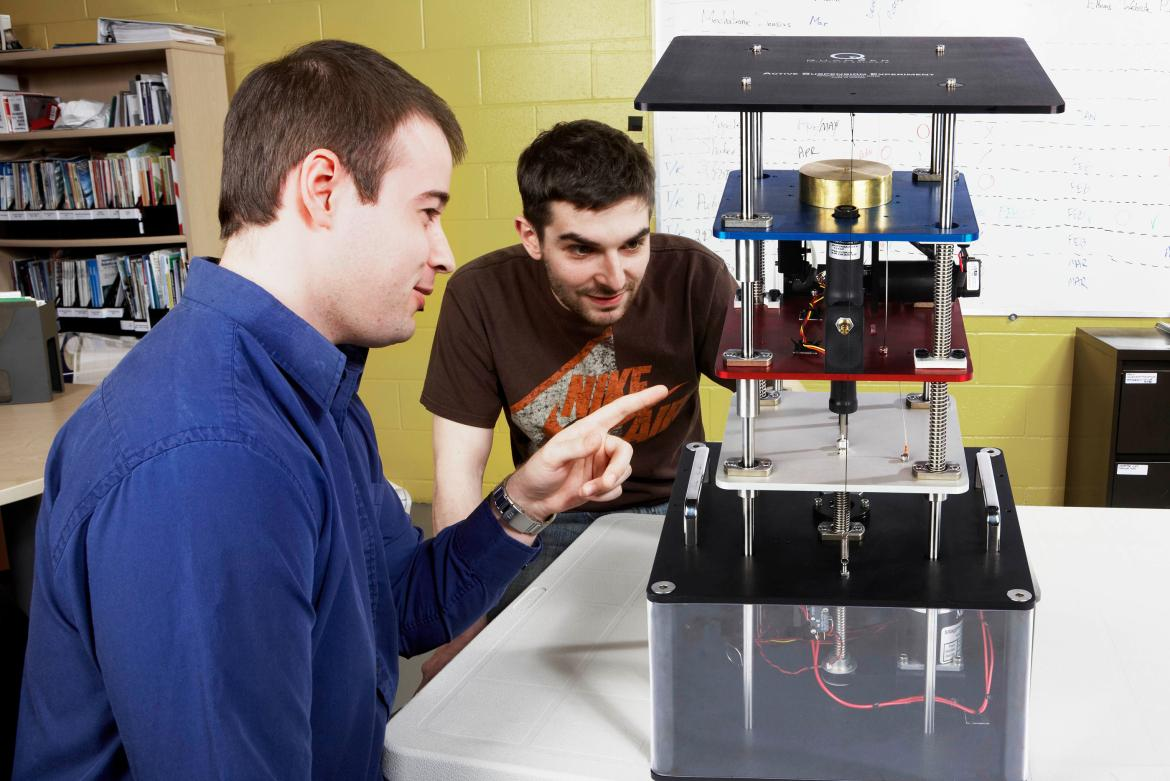

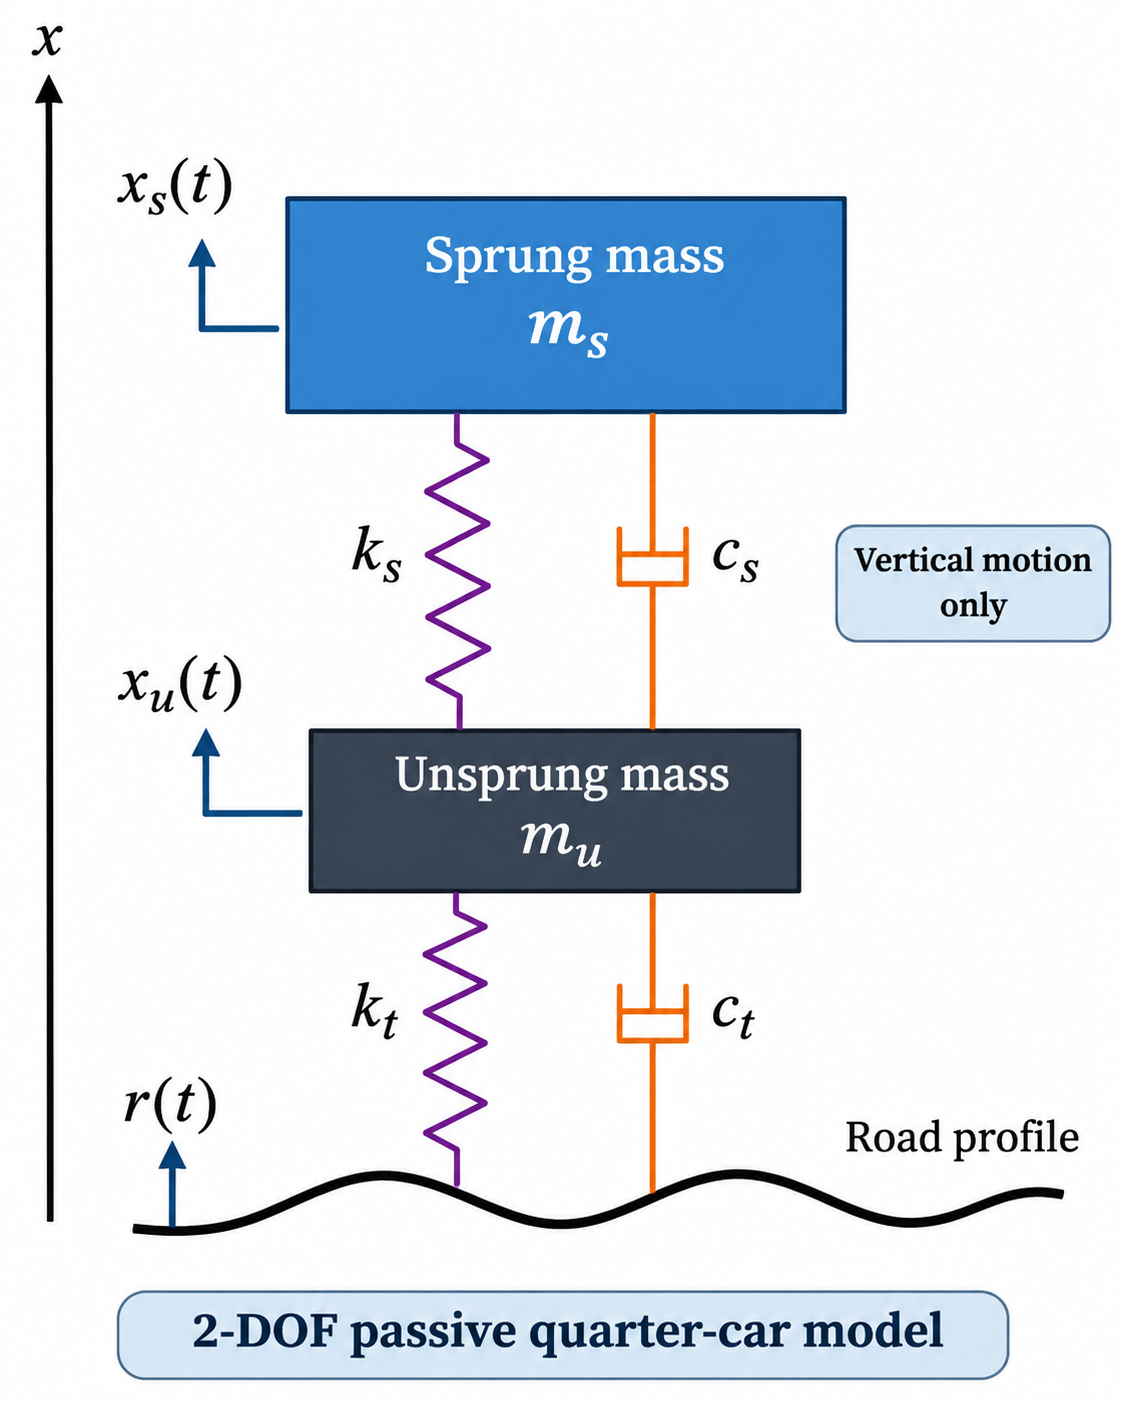

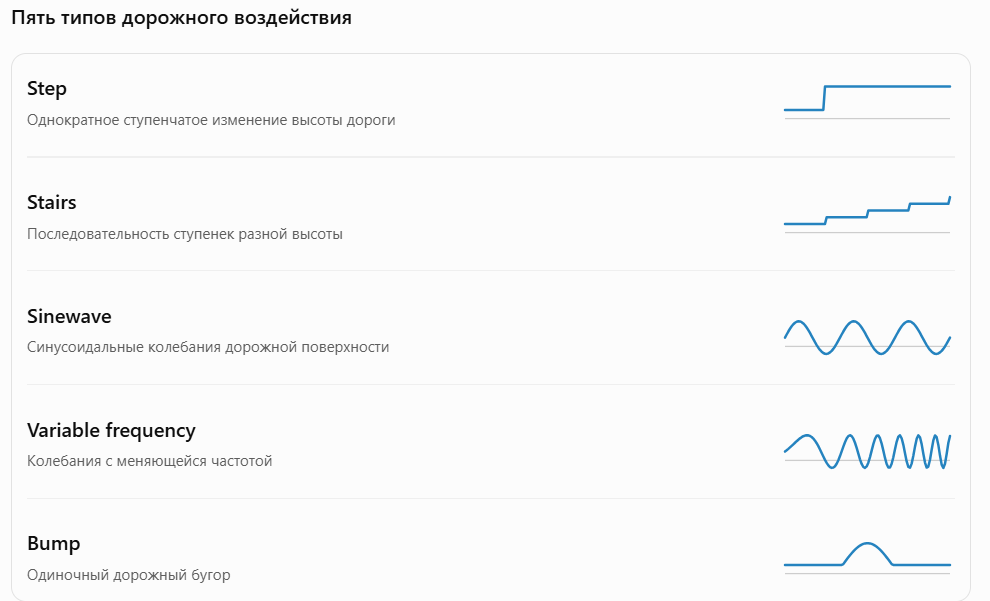

### 1. Физическая модель и структурный граф

Состояние $z=(x_s,x_u,v_s,v_u)$: вертикальные положения и скорости кузова и колеса; $r$ — входное дорожное перемещение. Обе координаты $x_s,x_u$ независимы, поэтому система действительно имеет **2 степени свободы**, хотя движение происходит по одной вертикальной оси.

$$
\begin{aligned}
m_s\ddot x_s &= -k_s(x_s-x_u)-c_s(\dot x_s-\dot x_u),\\
m_u\ddot x_u &= k_s(x_s-x_u)+c_s(\dot x_s-\dot x_u)-k_t(x_u-r)-c_t(\dot x_u-\dot r).
\end{aligned}
$$


Оцениваемый вектор $\theta=(k_s,k_t,c_s,c_t)$, массы фиксированы: $m_s=2.45$ кг, $m_u=1$ кг. Справочные значения параметров — $(900,2500,7.5,5)$ в единицах Н/м и Н·с/м.


In [ ]:
# Пакеты: numpy, scipy, pandas, openpyxl, requests, matplotlib, networkx, torch.
# При необходимости выполните один раз:
# %pip install numpy scipy pandas openpyxl requests matplotlib networkx torch
from pathlib import Path
import numpy as np
import pandas as pd


import matplotlib
import matplotlib.pyplot as plt

from IPython.display import display, Image
from io import BytesIO

def show_in_colab(*args, **kwargs):
    for num in plt.get_fignums():
        fig = plt.figure(num)

        buffer = BytesIO()
        fig.savefig(
            buffer,
            format="png",
            dpi=150,
            bbox_inches="tight"
        )

        display(Image(data=buffer.getvalue()))
        buffer.close()
        plt.close(fig)

# Заменяем стандартный show()
plt.show = show_in_colab

import networkx as nx
from IPython.display import display

import lab3_quanser_core as core  # отдельный модуль с функциями и классами

SEED = 42
np.random.seed(SEED)
OUT = Path("outputs")
OUT.mkdir(exist_ok=True)
plt.rcParams.update({"figure.figsize": (9, 3.5), "font.family": "DejaVu Sans", "axes.grid": True})
print("Источник:", core.DOI)
print("Состояние: [x_s, x_u, v_s, v_u]; параметры:", core.PARAMS)

Источник: doi:10.7910/DVN/XGTWSJ
Состояние: [x_s, x_u, v_s, v_u]; параметры: ('k_s', 'k_t', 'c_s', 'c_t')


### 2. Самопроверка кода (отдельные тесты)

In [ ]:
# Тестовые синтетические ряды используются ТОЛЬКО в тестах, не как основной датасет.
# Файл test_lab3_quanser.py поставляется рядом с ноутбуком.
import test_lab3_quanser as tests

tests.test_transfer_static_limit()
tests.test_two_dimensional_ode_and_spectrum()
tests.test_xlsx_parser_and_intervention()
tests.test_fetch_quanser_cache_and_403()
tests.test_regularization_and_computation_graph()
print("Тесты: OK (модель, формат XLSX, SMC, KS, RealNVP, DAG)")

Тесты: OK (модель, формат XLSX, SMC, KS, RealNVP, DAG)


### 3. Загрузка реальных измерений Quanser

Источник: [Harvard Dataverse — Quanser Experimental Dataset](https://doi.org/10.7910/DVN/XGTWSJ).

Нужны **ровно три оригинальных файла**: `Body Displacement Data.xlsx`, `Tire Position Data.xlsx`, `Vertical Displacement Error.xlsx`. Сначала загрузчик проверяет `data/quanser` и, если файлов нет, пробует прямые публичные ссылки на конкретные файлы Harvard Dataverse **без обращения к API метаданных**. Копии сверяются с опубликованными контрольными суммами MD5.


При необходимости прямые ссылки: [положение кузова](https://dataverse.harvard.edu/api/access/datafile/12133334), [положение колеса](https://dataverse.harvard.edu/api/access/datafile/12133331), [ошибка перемещения](https://dataverse.harvard.edu/api/access/datafile/12133329).

**Восстановление дороги:** рабочая конвенция $e=r-x_s$, то есть $r=x_s+e$. Поскольку в кратких метаданных направление разности не уточнено, параметр `ROAD_ERROR_SIGN` ниже следует подтвердить по эксперименту. Ни синтетические, ни другие данные не подставляются вместо оригинальных XLSX.

In [ ]:
PROFILE = "Step"
MODE = "Passive"
ROAD_ERROR_SIGN = +1  # e = road - body; если автор использовал e = body - road, поставить -1
COLUMN_OVERRIDES = {}  # при нестандартной структуре: {'Body Displacement Data.xlsx': {'sheet':0,'time_col':0,'value_col':1,'start_row':2}}

print("Папка для оригинальных XLSX:", Path("data/quanser").resolve())
files = core.fetch_quanser("data/quanser")
for title, local_path in files.items():
    print(f"{title}: {local_path.stat().st_size/1e6:.2f} MB")

# Прозрачная проверка первых строк оригинальной книги (до автоматического выбора колонок).
display(pd.read_excel(files["Body Displacement Data.xlsx"], header=None, nrows=6).iloc[:, :15])

exp = core.make_experiment(files, profile=PROFILE, mode=MODE,
                           road_sign=ROAD_ERROR_SIGN,
                           overrides=COLUMN_OVERRIDES, n_points=2400)
print(exp.info)
print(f"Общие измерения: {len(exp.t)} отсчётов; t=[{exp.t[0]:.3f}, {exp.t[-1]:.3f}] с")
assert len(exp.t) >= 100 and np.std(exp.x_s) > 0 and np.std(exp.x_u) > 0

Папка для оригинальных XLSX: /content/data/quanser
Body Displacement Data.xlsx: 5.65 MB
Tire Position Data.xlsx: 4.67 MB
Vertical Displacement Error.xlsx: 4.34 MB


,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14
0,Step,NaN,NaN,NaN,NaN,NaN,NaN,Stairs,NaN,NaN,NaN,NaN,NaN,NaN,Variable freq
1,Time,Road,passive,PID,Fuzzy,FPID,NaN,Time,Road,passive,PID,Fuzzy,FPID,NaN,Time
2,0,0,0,0,0,0,NaN,0,0.005,0,0,0,0,NaN,0
3,0.001,0,0,0,0,0,NaN,0.001,0.005,0,0,0,0,NaN,0.001
4,0.002,0,0,0,0,0,NaN,0.002,0.005,0,0,0,0,NaN,0.002
5,0.003,0,0,0,0,0,NaN,0.003,0.005,0,0,0,0,NaN,0.003


Body Displacement Data.xlsx: sheet=Sheet1, time_col=0, value_col=2
Tire Position Data.xlsx: sheet=Sheet1, time_col=0, value_col=1
Vertical Displacement Error.xlsx: sheet=Sheet1, time_col=0, value_col=1; road = body + (1)*error
Общие измерения: 2400 отсчётов; t=[0.000, 16.383] с


### 4. Реальные данные и требуемая 3D-визуализация с учётом времени

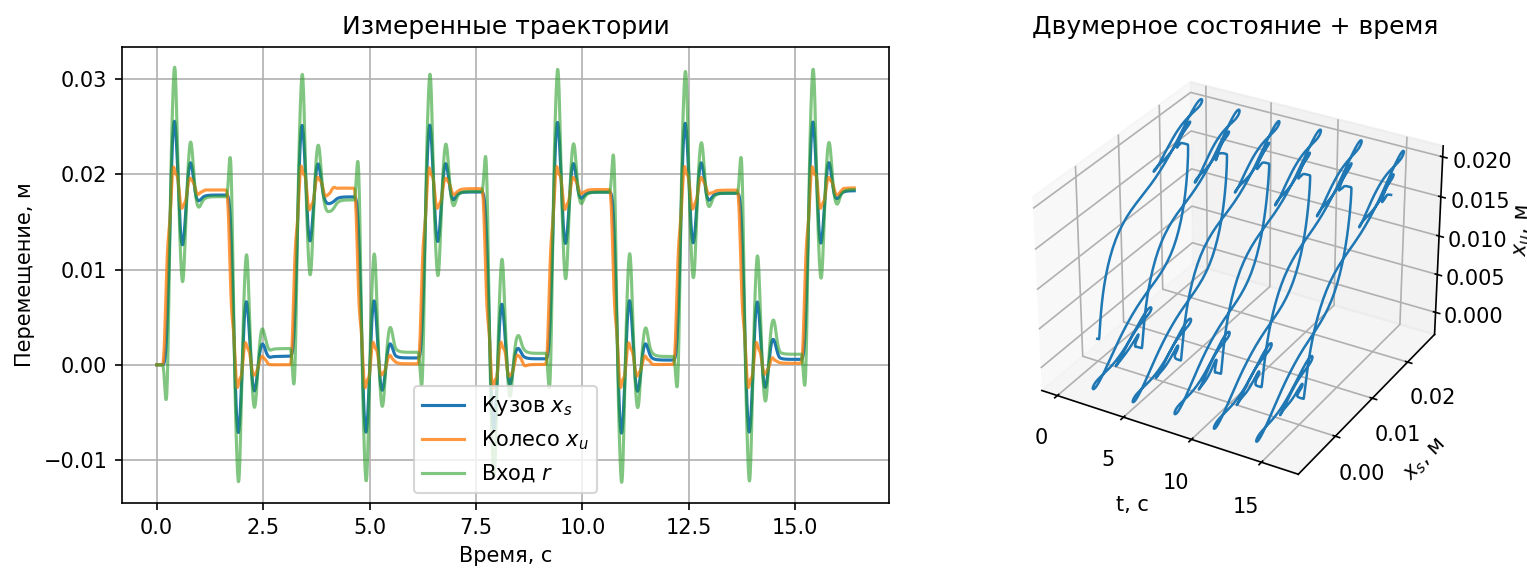

In [ ]:
fig = plt.figure(figsize=(11,4.0))
ax1 = fig.add_subplot(121)
ax1.plot(exp.t, exp.x_s, label="Кузов $x_s$")
ax1.plot(exp.t, exp.x_u, label="Колесо $x_u$", alpha=.8)
ax1.plot(exp.t, exp.road, label="Вход $r$", alpha=.6)
ax1.set(xlabel="Время, с", ylabel="Перемещение, м", title="Измеренные траектории")
ax1.legend()
ax2 = fig.add_subplot(122, projection="3d")
ax2.plot(exp.t, exp.x_s, exp.x_u, lw=1.2)
ax2.set(xlabel="t, с", ylabel="$x_s$, м", zlabel="$x_u$, м", title="Двумерное состояние + время")
plt.tight_layout()
plt.show()

### 5. Подготовка обучающей и проверочной выборок

Формируем две непересекающиеся части данных для оценки параметров и проверки качества графов.

In [ ]:
# Подготовка данных для уже используемых в ноутбуке процедур оценки параметров.
full_spec = core.make_spectrum(exp, n_freq=24)
train_spec, test_spec = core.split_spectrum(full_spec)
print(f"Точек: {len(full_spec.omega)}; обучение: {len(train_spec.omega)}; проверка: {len(test_spec.omega)}")


Точек: 24; обучение: 16; проверка: 8


### 6. Интервенции занулением: $x_s$, $x_u$, $r$

Для исходных наблюдений и модифицированных данных сравниваем распределения параметров $\theta=(k_s,k_t,c_s,c_t)$ с помощью SMC и статистики Колмогорова–Смирнова.

- **`zero x_s`**: измерения кузова заменяем нулём, остальные сигналы оставляем без изменений.
- **`zero x_u`**: измерения колеса заменяем нулём, остальные сигналы оставляем без изменений.
- **`zero r`**: отдельный диагностический случай: при исчезновении известного входного возбуждения в принятой модели нельзя корректно использовать прежнюю процедуру идентификации. Для демонстрации неопределённости берём априорную выборку, **не выдавая её за результат SMC по занулённому входу**.

Для штрафа за исключение физических связей используются только KS-статистики интервенций `zero x_s` и `zero x_u`.

,intervention,method,parameter,median_original,median_zeroed,KS_D,KS_pvalue
0,zero x_s,SMC,k_s,197.6440,183.9792,0.7208,0.0000
1,zero x_s,SMC,k_t,6890.3839,5578.4107,0.4500,0.0000
2,zero x_s,SMC,c_s,34.3616,21.4018,0.9875,0.0000
3,zero x_s,SMC,c_t,7.0809,3.6844,0.8375,0.0000
4,zero x_u,SMC,k_s,197.6440,198.2913,0.0833,0.3758
5,zero x_u,SMC,k_t,6890.3839,8426.0355,0.3625,0.0000
6,zero x_u,SMC,c_s,34.3616,33.0422,0.2083,0.0001
7,zero x_u,SMC,c_t,7.0809,4.7681,0.5125,0.0000


KS-веса физических каналов (max по двум измеряемым выходам):


,parameter,KS_x_s,KS_x_u,KS_D,decision
0,k_s,0.7208,0.0833,0.7208,сохранить физический канал
1,k_t,0.4500,0.3625,0.4500,сохранить физический канал
2,c_s,0.9875,0.2083,0.9875,сохранить физический канал
3,c_t,0.8375,0.5125,0.8375,сохранить физический канал


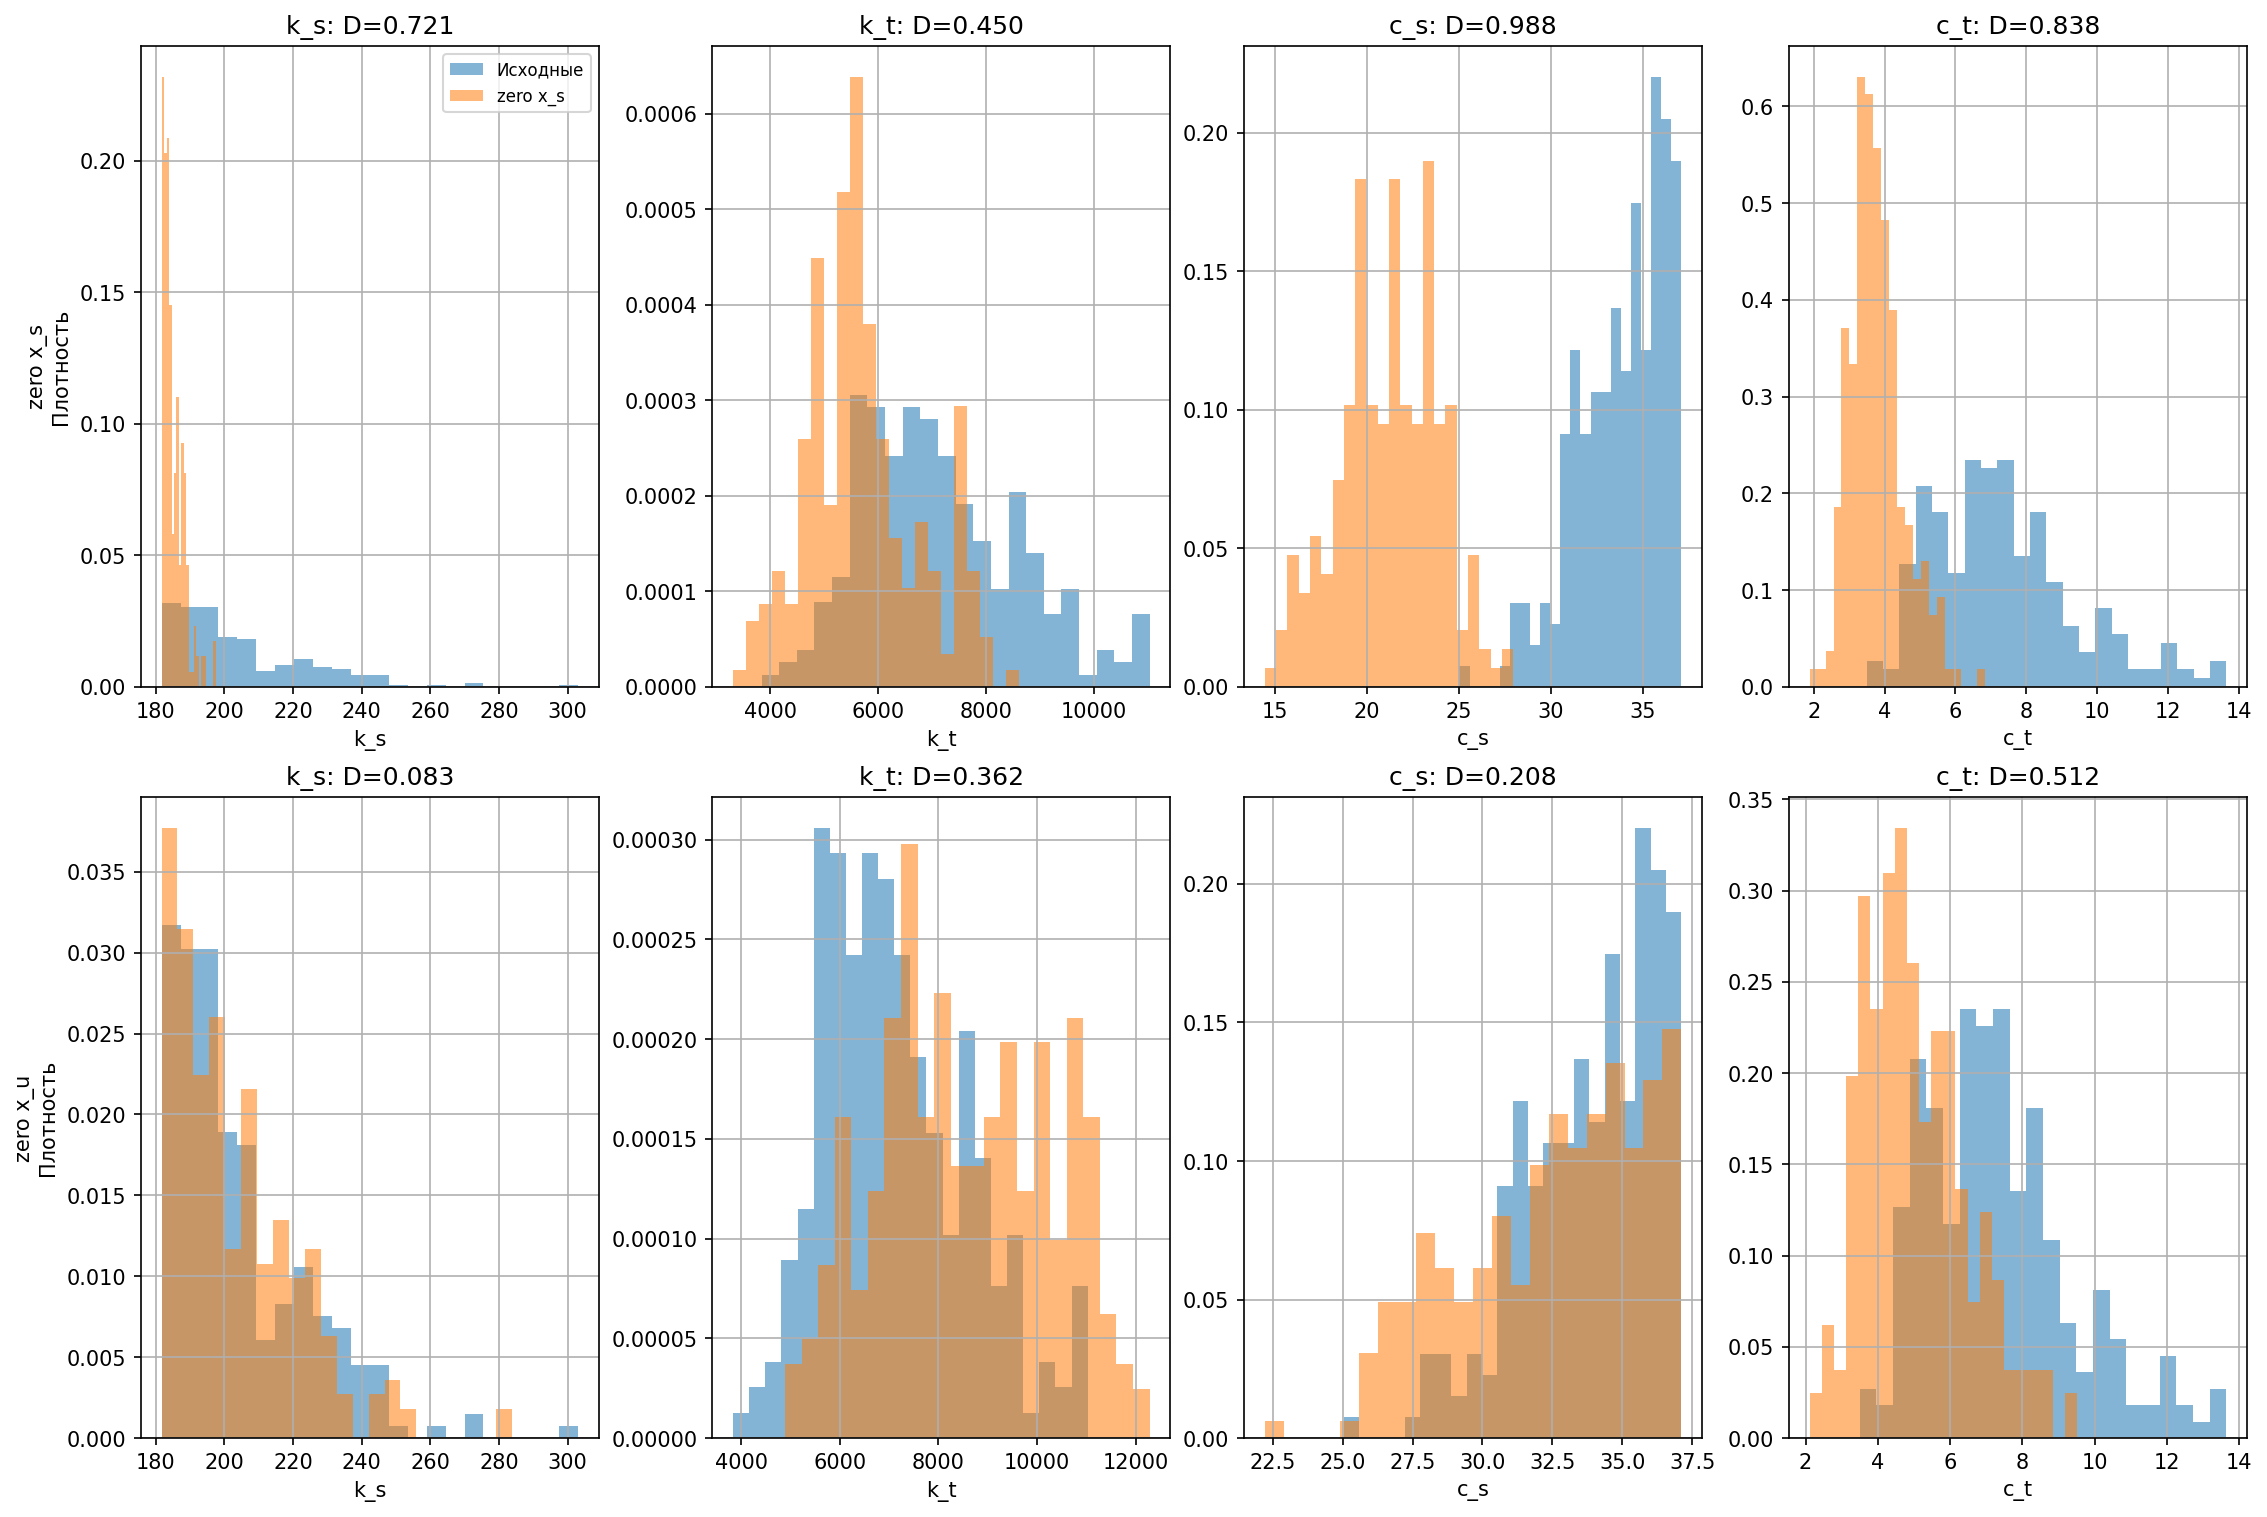

In [ ]:
from scipy.stats import truncnorm

N_PARTICLES = 240
posterior_original = core.smc(train_spec, n_particles=N_PARTICLES, seed=SEED)

# Исходные копии измерений и три варианта зануления.
zero_exps = {
    "x_s": core.Experiment(exp.t.copy(), np.zeros_like(exp.x_s), exp.x_u.copy(),
                            exp.road.copy(), "zero x_s", exp.info),
    "x_u": core.Experiment(exp.t.copy(), exp.x_s.copy(), np.zeros_like(exp.x_u),
                            exp.road.copy(), "zero x_u", exp.info),
    "r": core.Experiment(exp.t.copy(), exp.x_s.copy(), exp.x_u.copy(),
                          np.zeros_like(exp.road), "zero r", exp.info)
}

posteriors = {}
ks_tables = []

# При занулении выходного измерения фиксируем всё остальное и оцениваем параметры SMC.
for i, variable in enumerate(("x_s", "x_u")):
    H_zero = train_spec.H.copy()
    H_zero[:, i] = 0.0
    spec_zero = core.Spectrum(train_spec.omega.copy(), H_zero,
                              train_spec.weight.copy())
    posteriors[variable] = core.smc(spec_zero,
                                    n_particles=N_PARTICLES, seed=SEED + i + 1)

# Для zero r — только диагностический априорный образец; это НЕ третий запуск SMC.
prior_rng = np.random.default_rng(SEED + 3)
prior_log = truncnorm.rvs(-1.6 / 0.5, 1.6 / 0.5,
                          loc=np.log(core.NOMINAL), scale=0.5,
                          size=(N_PARTICLES, 4), random_state=prior_rng)
posteriors["r"] = np.exp(prior_log)

for variable in ("x_s", "x_u"):
    table = core.compare_posteriors(posterior_original, posteriors[variable])
    table.insert(0, "intervention", f"zero {variable}")
    table.insert(1, "method", "SMC" if variable != "r" else "prior (diagnostic)")
    ks_tables.append(table)

ks_all = pd.concat(ks_tables, ignore_index=True)
display(ks_all.round(4))
ks_all.to_csv(OUT / "smc_ks_results.csv", index=False)

# Для выбора структуры берём максимальную KS-статистику только по двум выходам.
ks_df = pd.DataFrame({"parameter": list(core.PARAMS)})
for variable in ("x_s", "x_u"):
    ks_df[f"KS_{variable}"] = (ks_all.loc[
        ks_all["intervention"].eq(f"zero {variable}"), "KS_D"].to_numpy())
ks_df["KS_D"] = ks_df[["KS_x_s", "KS_x_u"]].max(axis=1)
ks_df["decision"] = np.where(ks_df["KS_D"] >= 0.20,
                              "сохранить физический канал", "удаление допустимо")
print("KS-веса физических каналов (max по двум измеряемым выходам):")
display(ks_df.round(4))
ks_df.to_csv(OUT / "smc_ks_graph_weights.csv", index=False)

fig, axs = plt.subplots(2, 4, figsize=(15, 10), constrained_layout=True)
for row, variable in enumerate(("x_s", "x_u")):
    for col, param in enumerate(core.PARAMS):
        ax = axs[row, col]
        D = ks_all.loc[(ks_all["intervention"] == f"zero {variable}") &
                       (ks_all["parameter"] == param), "KS_D"].iloc[0]
        ax.hist(posterior_original[:, col], bins=22, density=True, alpha=0.55,
                label="Исходные")
        ax.hist(posteriors[variable][:, col], bins=22, density=True, alpha=0.55,
                label=f"zero {variable}")
        ax.set_title(f"{param}: D={D:.3f}")
        ax.set_xlabel(param)
        if col == 0:
            ax.set_ylabel(f"zero {variable}\nПлотность")
axs[0, 0].legend(fontsize=8)
plt.show()


### 7. Целевая функция выбора графа

Каждый граф $G$ задаётся четырьмя включаемыми физическими каналами $b=(b_{k_s},b_{k_t},b_{c_s},b_{c_t})$.
При фиксированных оценках параметров сравниваем три требования:

$$
\boxed{
J_{\lambda,\mu}(G)
=\underbrace{E(G)}_{\text{ошибка}}
+\underbrace{\lambda\sum_j b_j}_{\text{сложность}}
+\underbrace{\mu\frac{\sum_jD_j(1-b_j)}{\sum_jD_j}}_{\text{штраф за исключение чувствительных каналов}}
}
$$

Здесь $D_j=\max(D_j^{(x_s)},D_j^{(x_u)})$ — статистика KS по двум экспериментам. Третье слагаемое — **эвристический структурный штраф**, а не доказательство причинности.

Коэффициенты $\lambda$ и $\mu$ ниже выделены в отдельные параметры. **Увеличение $\lambda$ должно поощрять более простые графы, но может существенно ухудшить точность $E(G)$.**

,mask,train_nrmse,test_nrmse,edges,intervention_penalty,J
0,1111,1.2051,0.4391,4,0.0000,0.4491
1,0111,1.0948,0.4144,3,0.2406,0.5904
2,1110,1.2066,0.4395,3,0.2796,0.6427
3,0110,1.0961,0.4147,2,0.5202,0.7838
4,1011,1.0047,0.9982,3,0.1502,1.1108
5,0101,1.1770,0.7707,2,0.5702,1.1749
6,0011,1.0007,0.9605,2,0.3908,1.2391
7,1010,1.0000,1.0000,2,0.4298,1.3058
8,1001,1.0045,0.9981,2,0.4798,1.3390
9,0100,1.1770,0.7707,1,0.8498,1.3680


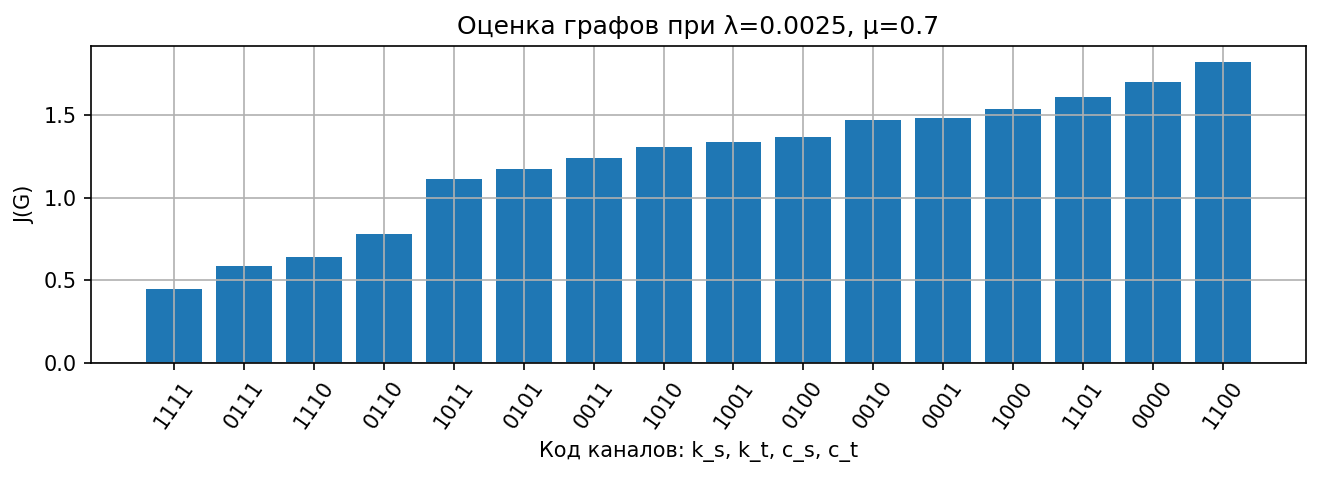

In [ ]:
# Основные веса функции качества. Измените их и перезапустите разделы 7–11.
COMPLEXITY_WEIGHT = 0.0025   # lambda: штраф за каждый включённый физический канал
INTERVENTION_WEIGHT = 0.7    # mu: штраф за исключение чувствительного канала

ranked = core.score_candidates(train_spec, test_spec, ks_df,
                               complexity_weight=COMPLEXITY_WEIGHT,
                               intervention_weight=INTERVENTION_WEIGHT)
display(ranked[["mask", "train_nrmse", "test_nrmse", "edges", "intervention_penalty", "J"]]
        .head(16).round(4))
ranked.to_csv(OUT / "candidate_graphs.csv", index=False)

plt.figure(figsize=(9, 3.3))
plt.bar(ranked["mask"].astype(str), ranked["J"])
plt.title(f"Оценка графов при λ={COMPLEXITY_WEIGHT:g}, μ={INTERVENTION_WEIGHT:g}")
plt.xlabel("Код каналов: k_s, k_t, c_s, c_t")
plt.ylabel("J(G)")
plt.xticks(rotation=55)
plt.tight_layout()
plt.show()


### 7.1. Что происходит при изменении коэффициентов регуляризации?

Физические параметры для каждой из 16 масок уже подобраны. Поэтому при изменении $\lambda$ и $\mu$ **не нужно заново обучать ODE**: достаточно пересчитать $J_{\lambda,\mu}(G)$ по неизменным ошибкам, количеству каналов и KS-штрафам.

Ниже показаны: (1) карта оптимальных масок при разных весах, (2) компромисс **ошибка / сложность** при фиксированном $\mu$, (3) графы для нескольких значений $\lambda$. Для очень сильной регуляризации может победить даже пустой граф `0000`: он прост, но плохо объясняет данные.

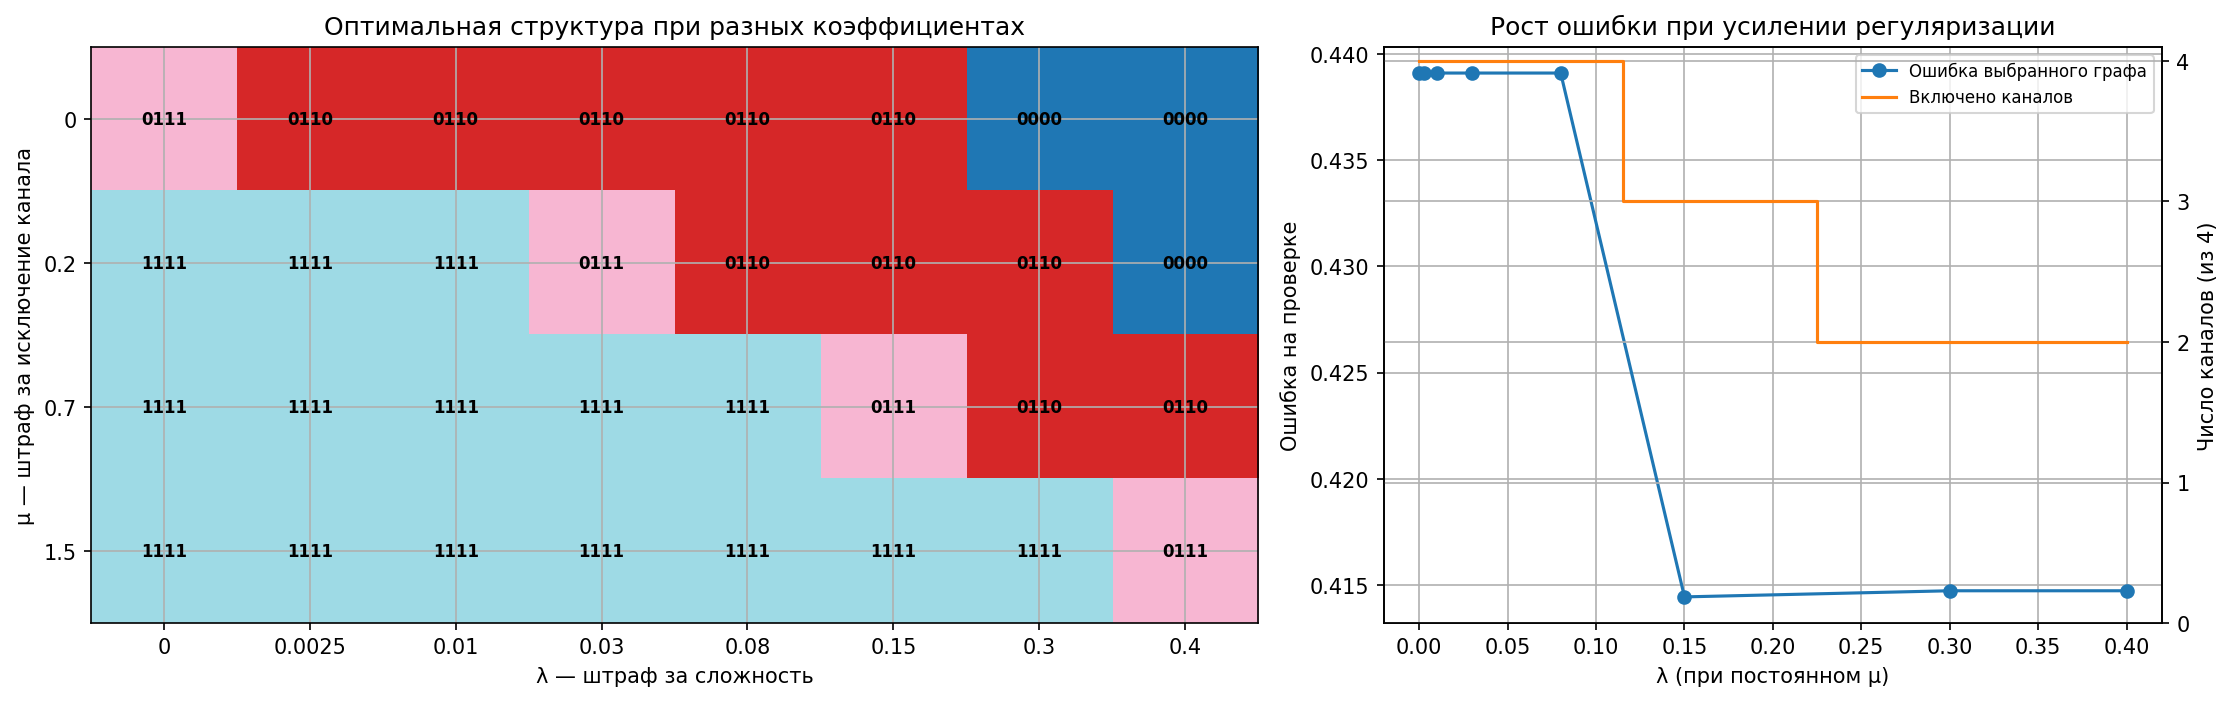

Победители при фиксированном μ:


,lambda_complexity,mu_intervention,best_mask,edges,test_nrmse,J
16,0.0000,0.7,1111,4,0.4391,0.4391
17,0.0025,0.7,1111,4,0.4391,0.4491
18,0.0100,0.7,1111,4,0.4391,0.4791
19,0.0300,0.7,1111,4,0.4391,0.5591
20,0.0800,0.7,1111,4,0.4391,0.7591
21,0.1500,0.7,0111,3,0.4144,1.0329
22,0.3000,0.7,0110,2,0.4147,1.3788
23,0.4000,0.7,0110,2,0.4147,1.5788


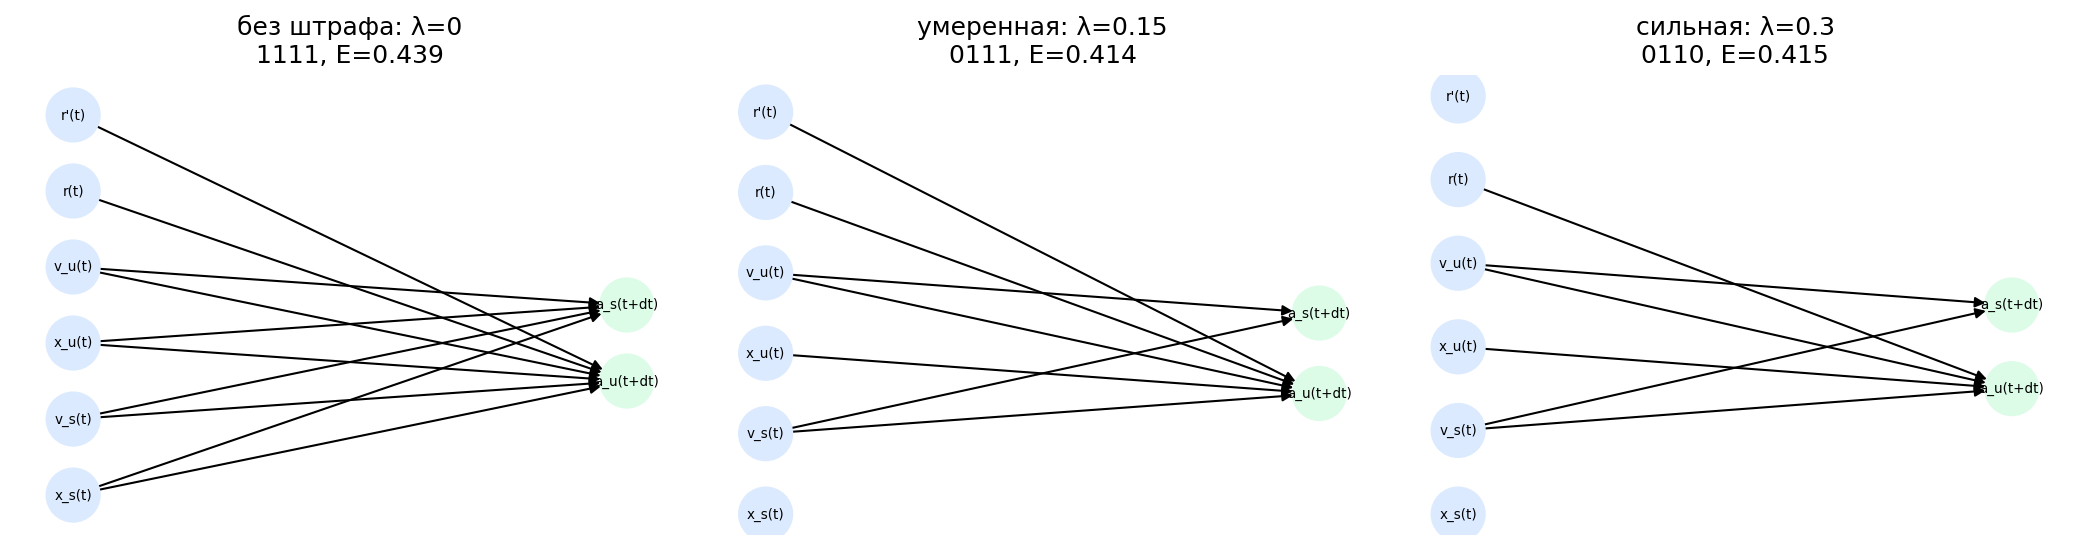

In [ ]:
# Изменяемые диапазоны весов: для экспериментов достаточно перезапустить эту ячейку.
LAMBDA_GRID = [0.0, 0.0025, 0.01, 0.03, 0.08, 0.15, 0.3, 0.4]
MU_GRID = [0.0, 0.2, 0.7, 1.5]

sweep = core.regularization_sweep(ranked, LAMBDA_GRID, MU_GRID)
sweep.to_csv(OUT / "regularization_sweep.csv", index=False)

# Карта структур: в ячейках указывается четырёхбитная маска, цвет — тип графа.
unique_codes = sorted(sweep["best_mask"].unique())
mask_id = {m: i for i, m in enumerate(unique_codes)}
mask_grid = sweep.pivot(index="mu_intervention", columns="lambda_complexity", values="best_mask")
color_grid = mask_grid.apply(lambda col: col.map(mask_id)).to_numpy(dtype=float)
fig, axs = plt.subplots(1, 2, figsize=(15, 4.8), gridspec_kw={"width_ratios": [1.5, 1]})
cmap = plt.get_cmap("tab20", max(2, len(unique_codes)))
axs[0].imshow(color_grid, cmap=cmap, vmin=-0.5, vmax=max(1, len(unique_codes)-0.5), aspect="auto")
axs[0].set(xticks=np.arange(len(mask_grid.columns)),
           yticks=np.arange(len(mask_grid.index)),
           xticklabels=[f"{x:g}" for x in mask_grid.columns],
           yticklabels=[f"{x:g}" for x in mask_grid.index],
           xlabel="λ — штраф за сложность", ylabel="μ — штраф за исключение канала",
           title="Оптимальная структура при разных коэффициентах")
for ii in range(mask_grid.shape[0]):
    for jj in range(mask_grid.shape[1]):
        axs[0].text(jj, ii, mask_grid.iloc[ii, jj], ha="center", va="center",
                    fontsize=8, fontweight="bold", color="black")

fixed = sweep[np.isclose(sweep["mu_intervention"], INTERVENTION_WEIGHT)].sort_values("lambda_complexity")
axs[1].plot(fixed["lambda_complexity"], fixed["test_nrmse"], "o-", label="Ошибка выбранного графа")
axs[1].set(xlabel="λ (при постоянном μ)", ylabel="Ошибка на проверке",
           title="Рост ошибки при усилении регуляризации")
ax2=axs[1].twinx()
ax2.step(fixed["lambda_complexity"], fixed["edges"], where="mid", color="tab:orange",
         label="Включено каналов")
ax2.set_ylabel("Число каналов (из 4)")
ax2.set_yticks(range(5))
handles, labels = axs[1].get_legend_handles_labels()
handles2, labels2 = ax2.get_legend_handles_labels()
axs[1].legend(handles + handles2, labels + labels2, loc="best", fontsize=8)
plt.tight_layout()
plt.show()

print("Победители при фиксированном μ:")
display(fixed[["lambda_complexity", "mu_intervention", "best_mask", "edges", "test_nrmse", "J"]].round(4))

# Три характерных режима: без штрафа, умеренный штраф и сильный штраф.
SCENARIOS = [("без штрафа", 0.0), ("умеренная", 0.15), ("сильная", 0.3)]
fig, axs = plt.subplots(1, 3, figsize=(14, 3.8))
for ax, (label, lam) in zip(axs, SCENARIOS):
    t = core.rescore_graphs(ranked, lam, INTERVENTION_WEIGHT)
    best_row = t.iloc[0]
    mask = core.mask_to_array(str(best_row["mask"]))
    g = core.dynamics_graph(mask)
    left = [n for n in g.nodes if "(t+dt)" not in n]
    right = [n for n in g.nodes if "(t+dt)" in n]
    pos = {n: (0, i) for i, n in enumerate(left)}
    pos.update({n: (2, 2.5-i) for i, n in enumerate(right)})
    nx.draw_networkx(g, pos, ax=ax, with_labels=True, node_size=650,
                     font_size=6.5, arrowsize=10,
                     node_color=["#dbeafe" if n in left else "#dcfce7" for n in g.nodes])
    ax.set_title(f"{label}: λ={lam:g}\n{best_row['mask']}, E={best_row['test_nrmse']:.3f}")
    ax.axis("off")
plt.tight_layout()
plt.show()


### 8. ЛР № 3, вариант 6: генерация графов RealNVP

**Алгоритм:**

1. Строим 16 кандидатных структур и оцениваем $J(G)$ (предыдущий раздел).
2. Отбираем 5 лучших и представляем каждую структуру 4-битным вектором; для обучения обратимого отображения выполняем **dequantization**: $u=1.25(2b-1)+\epsilon$, $\epsilon\sim N(0,0.3^2I)$.
3. Обучаем 4 слоя affine coupling (RealNVP), максимизируя правдоподобие этих непрерывных векторов.
4. Генерируем $z\sim N(0,I)$, получаем $u=f(z)$, после чего $b_j=\mathbb{1}\{u_j>0\}$. Последняя бинаризация **не входит** в обратимое преобразование. Сравниваем выборки на шагах 0, $T/2$, $T$.
5. Сохраняем все сгенерированные маски; выбираем предпочтительный граф **по заранее определённому $J(G)$**, а не только по частоте сэмплирования.

**Корректность упрощения:** coupling-слои биективны для непрерывных входов и допускают вычисление якобиана, поэтому обучается именно нормализующий поток. Бинаризация создаёт графы из непрерывных сэмплов, но не является точной дискретной likelihood-моделью GraphNVP.

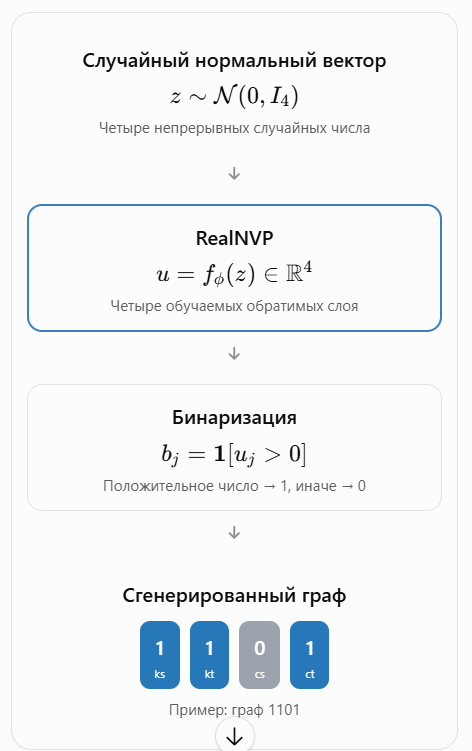

,epoch,mean_J,median_J,best_J,unique_graphs
0,0,1.1275,1.2391,0.4491,16
1,500,0.4975,0.4491,0.4491,5
2,1000,0.5090,0.4491,0.4491,6


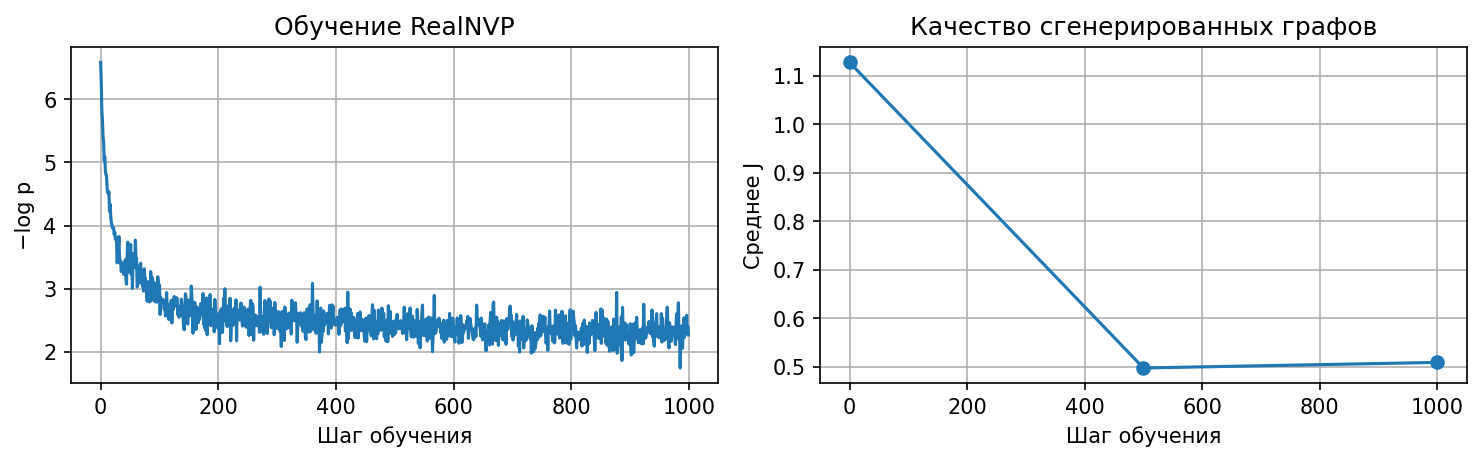

In [ ]:
flow, loss_history, sample_history = core.learn_graph_flow(ranked, epochs=1000,
                                                         n_samples=2000, seed=SEED)
progress = core.graph_sample_summary(sample_history, ranked)
display(progress.round(4))

records=[]
J_lookup=dict(zip(ranked["mask"], ranked["J"]))
for epoch, sample in sample_history:
    for row in sample:
        code_mask="".join(str(int(b)) for b in row)
        records.append({"epoch": epoch,"mask": code_mask,"J": J_lookup[code_mask]})
generated = pd.DataFrame(records)
generated.to_csv(OUT / "generated_graph_samples.csv", index=False)

fig, axs = plt.subplots(1,2,figsize=(10,3.2))
axs[0].plot(loss_history)
axs[0].set(xlabel="Шаг обучения", ylabel="−log p", title="Обучение RealNVP")
axs[1].plot(progress["epoch"], progress["mean_J"], 'o-')
axs[1].set(xlabel="Шаг обучения", ylabel="Среднее J", title="Качество сгенерированных графов")
plt.tight_layout()
plt.show()

### 8.1. Эмпирическое распределение графов, получаемое RealNVP

Показываем **все 16 возможных масок**, а не только наиболее частый граф. Частота появления маски среди сэмплов — оценка $\widehat P_{\phi}(G)$ после пороговой дискретизации выхода потока. Сравниваем начало, середину и конец обучения с целевыми весами пяти лучших графов. Дополнительно смотрим маргинальные вероятности включения каждого из четырёх каналов.

Распределение 16 графов (строки — маски, столбцы — шаги обучения):


epoch,0,500,1000
mask,,,
0000,0.042,0.000,0.000
0001,0.026,0.000,0.000
0010,0.070,0.000,0.000
0011,0.030,0.000,0.000
0100,0.049,0.000,0.000
0101,0.036,0.000,0.000
0110,0.115,0.018,0.027
0111,0.073,0.150,0.160
1000,0.082,0.000,0.000


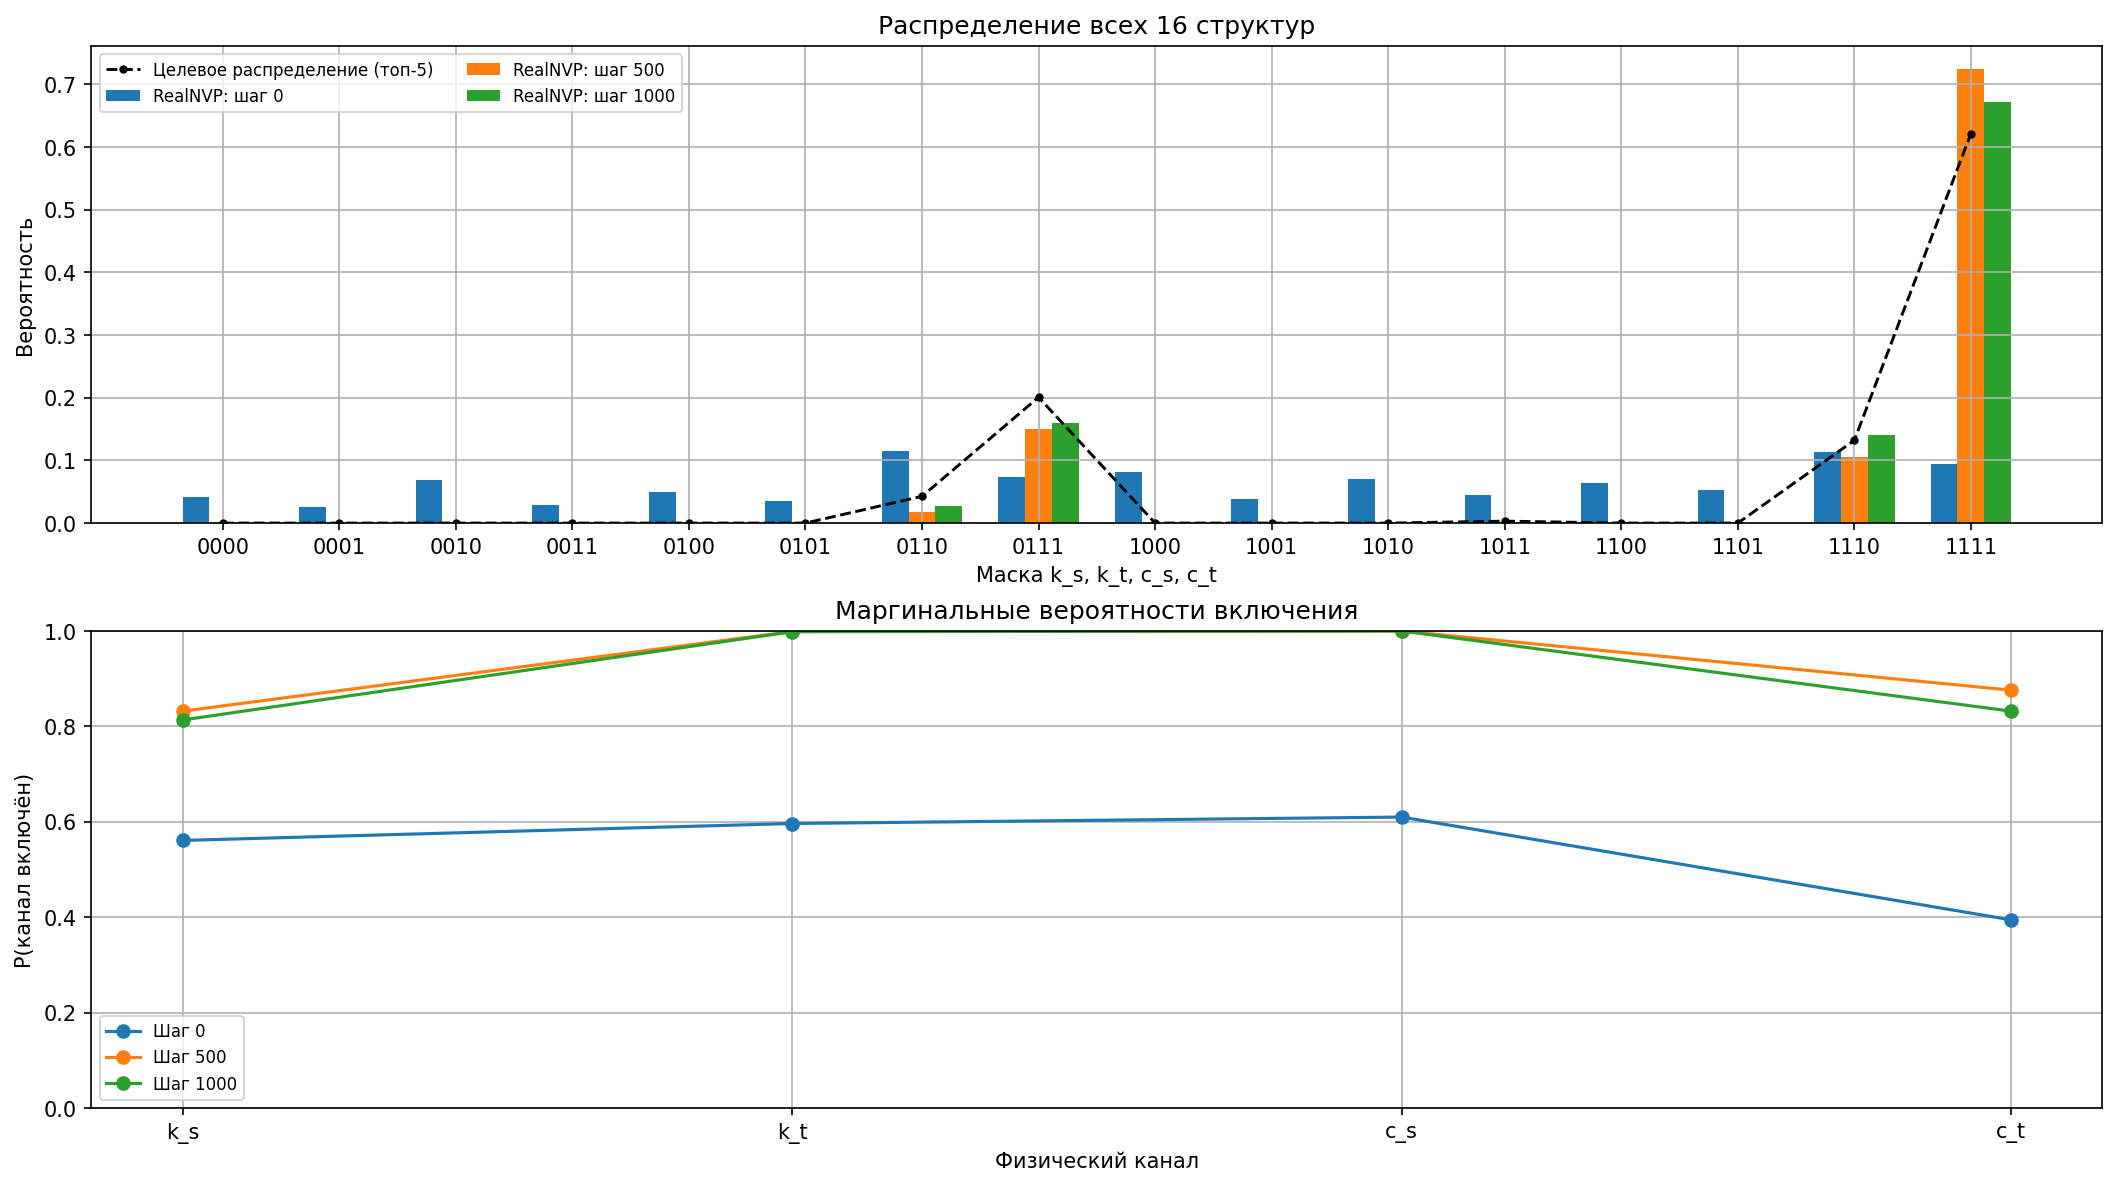

In [ ]:
# Частоты графов по эпохам RealNVP. Указаны ВСЕ 16 масок, в том числе редкие.
ALL_CODES = sorted("".join(map(str, row.astype(int))) for row in core.ALL_MASKS)
distribution_records = []
marginal_records = []
for epoch, bit_samples in sample_history:
    codes = pd.Series(["".join(map(str, row)) for row in bit_samples])
    prob = codes.value_counts(normalize=True).reindex(ALL_CODES, fill_value=0.0)
    for mask, p in prob.items():
        distribution_records.append({"epoch": int(epoch), "mask": mask,
                                     "probability": float(p),
                                     "count": int(round(p*len(codes)))})
    marg = bit_samples.mean(axis=0)
    for j, name in enumerate(core.PARAMS):
        marginal_records.append({"epoch": int(epoch), "parameter": name,
                                 "p_enabled": float(marg[j])})

graph_distribution = pd.DataFrame(distribution_records)
bit_marginals = pd.DataFrame(marginal_records)
graph_distribution.to_csv(OUT / "realnvp_graph_distribution.csv", index=False)
bit_marginals.to_csv(OUT / "realnvp_bit_marginals.csv", index=False)

print("Распределение 16 графов (строки — маски, столбцы — шаги обучения):")
display(graph_distribution.pivot(index="mask", columns="epoch", values="probability").round(3))

# Обучающее распределение на лучших пяти масках (для сравнения с потоком).
reference = np.zeros(len(ALL_CODES))
select = ranked.sort_values("J").head(5)
raw_w = np.exp(-8 * (select["J"].to_numpy() - select["J"].min()))
for mask, p in zip(select["mask"], raw_w/raw_w.sum()):
    reference[ALL_CODES.index(str(mask))] = p

fig, axs = plt.subplots(2, 1, figsize=(14, 7.8), constrained_layout=True)
epochs = sorted(graph_distribution["epoch"].unique())
x = np.arange(len(ALL_CODES))
bar_width = 0.23
for j, epoch in enumerate(epochs):
    p = graph_distribution.loc[graph_distribution["epoch"] == epoch].set_index("mask")["probability"]
    axs[0].bar(x + (j-1)*bar_width, p.reindex(ALL_CODES).to_numpy(),
               width=bar_width, label=f"RealNVP: шаг {epoch}")
axs[0].plot(x, reference, "k.--", lw=1.4, label="Целевое распределение (топ-5)")
axs[0].set(xticks=x, xticklabels=ALL_CODES, xlabel="Маска k_s, k_t, c_s, c_t",
           ylabel="Вероятность", title="Распределение всех 16 структур")
axs[0].legend(ncol=2, fontsize=8)

for epoch in epochs:
    p = bit_marginals[bit_marginals["epoch"] == epoch].set_index("parameter")["p_enabled"]
    axs[1].plot(range(4), p.reindex(core.PARAMS).to_numpy(), "o-", label=f"Шаг {epoch}")
axs[1].set(xticks=range(4), xticklabels=core.PARAMS, ylim=(0, 1),
           ylabel="P(канал включён)", xlabel="Физический канал",
           title="Маргинальные вероятности включения")
axs[1].legend(fontsize=8)
plt.show()


### 8.2. Как регуляризация меняет **распределение** RealNVP

Изменение $\lambda$ и $\mu$ меняет набор предпочтительных графов. Чтобы проверить не только минимум $J$, но и **генеративное поведение**, обучаем два дополнительных небольших потока при других весах. Исходный обученный поток повторно не обучаем. При сильном штрафе за сложность простые графы должны появляться чаще, но их ошибка может быть большой.

Ниже дополнительные потоки обучаются 700 шагов (основной — 3500), поэтому сравнение качественное, а не идеально контролируемое по бюджету. Для строгого сравнения можно увеличить `SCENARIO_EPOCHS` до 3500.

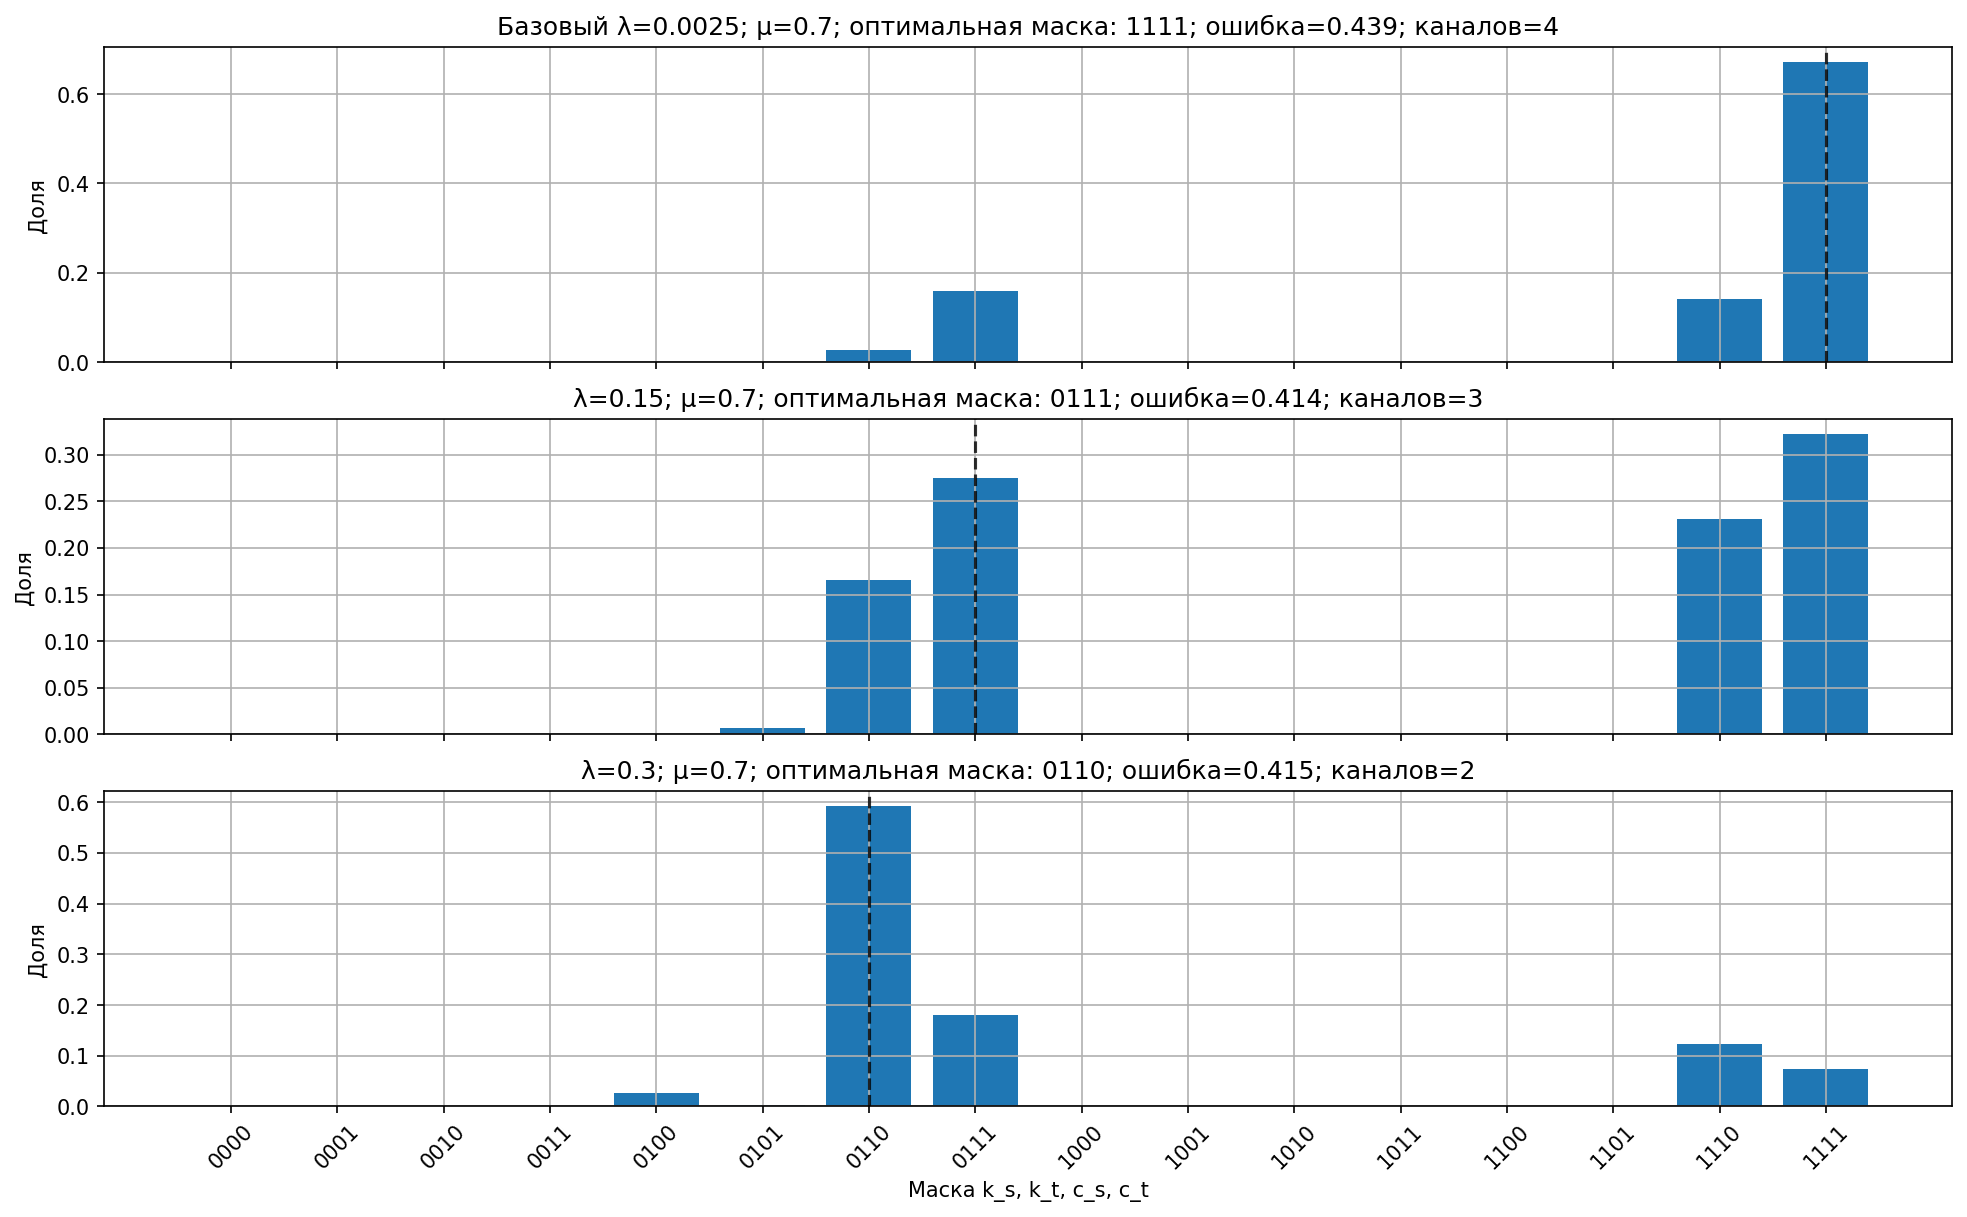

Пунктир показывает оптимальный граф по J, столбцы — частоты RealNVP.


In [ ]:
# Два дополнительных режима весов; используют те же ошибки кандидатов, что и основной прогон.
SCENARIO_EPOCHS = 700
SCENARIO_SAMPLES = 2000

# Выбираем два режима, в которых предпочтительная маска отличается от базовой,
# если такие режимы присутствуют в проведённом исследовании коэффициентов.
base_mask = str(ranked.iloc[0]["mask"])
weight_options = sweep.sort_values(["mu_intervention", "lambda_complexity"])
choices = []
seen_masks = {base_mask}
for _, entry in weight_options[np.isclose(weight_options["mu_intervention"],
                                         INTERVENTION_WEIGHT)].iterrows():
    new_mask = str(entry["best_mask"])
    if new_mask not in seen_masks:
        choices.append((f"λ={entry['lambda_complexity']:g}",
                        float(entry["lambda_complexity"]),
                        INTERVENTION_WEIGHT))
        seen_masks.add(new_mask)
    if len(choices) == 2:
        break
# Если минимумов только два, дополнительный сценарий с сильной регуляризацией
# всё равно будет показан (маски могут совпасть — это тоже результат эксперимента).
if len(choices) < 2:
    choices.append(("сильная λ", float(max(LAMBDA_GRID)), INTERVENTION_WEIGHT))
choices = choices[:2]

scenario_generated = [(f"Базовый λ={COMPLEXITY_WEIGHT:g}",
                       COMPLEXITY_WEIGHT, INTERVENTION_WEIGHT,
                       sample_history[-1][1])]
for idx, (label, lam, mu) in enumerate(choices):
    cand = core.rescore_graphs(ranked, lam, mu)
    alt_flow, _, alt_history = core.learn_graph_flow(cand,
                        epochs=SCENARIO_EPOCHS, n_samples=SCENARIO_SAMPLES,
                        seed=SEED + 101 + idx)
    scenario_generated.append((label, lam, mu, alt_history[-1][1]))

fig, axs = plt.subplots(len(scenario_generated), 1, figsize=(13, 8), sharex=True,
                        constrained_layout=True)
scenario_records = []
for ax, (label, lam, mu, bits) in zip(axs, scenario_generated):
    counts = pd.Series(["".join(map(str, row)) for row in bits]).value_counts(normalize=True)
    dist = counts.reindex(ALL_CODES, fill_value=0.0)
    ax.bar(np.arange(len(ALL_CODES)), dist.to_numpy())
    prefer = core.rescore_graphs(ranked, lam, mu).iloc[0]
    ax.axvline(ALL_CODES.index(str(prefer["mask"])), ls="--", color="black", alpha=0.8)
    ax.set(ylabel="Доля", title=f"{label}; μ={mu:g}; оптимальная маска: {prefer['mask']}"
           + f"; ошибка={prefer['test_nrmse']:.3f}; каналов={int(prefer['edges'])}")
    for mask, p in dist.items():
        scenario_records.append({"scenario": label, "lambda_complexity": lam,
                                 "mu_intervention": mu, "mask": mask,
                                 "probability": p})
axs[-1].set_xticks(np.arange(len(ALL_CODES)))
axs[-1].set_xticklabels(ALL_CODES, rotation=45)
axs[-1].set_xlabel("Маска k_s, k_t, c_s, c_t")
plt.show()

pd.DataFrame(scenario_records).to_csv(OUT / "regularization_flow_distributions.csv", index=False)
print("Пунктир показывает оптимальный граф по J, столбцы — частоты RealNVP.")


### 9. Последовательность сгенерированных графов и лучший структурный DAG

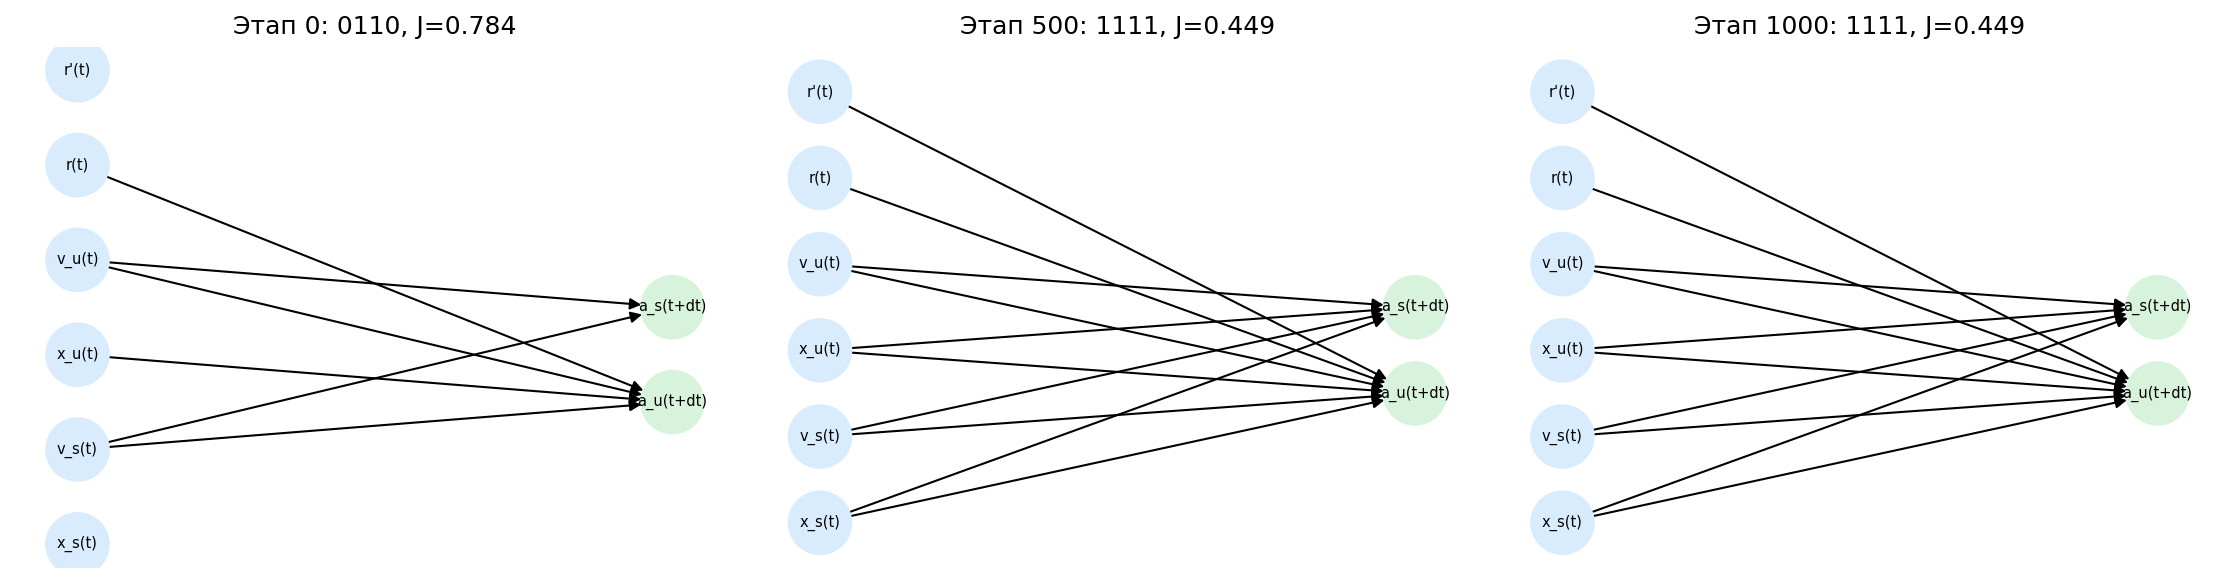

ЛУЧШИЙ ГРАФ: 1111 (порядок: ('k_s', 'k_t', 'c_s', 'c_t') )
Сохранены каналы: ['k_s', 'k_t', 'c_s', 'c_t']
Удалены каналы: []
Модельные параметры: {'k_s': np.float64(180.0), 'k_t': np.float64(12500.0), 'c_s': np.float64(37.5), 'c_t': np.float64(25.0)}
Проверочный NRMSE: 0.4391
Итог J: 0.4491
Матрица смежности по узлам:


,x_s(t),v_s(t),x_u(t),v_u(t),r(t),r'(t),a_s(t+dt),a_u(t+dt)
x_s(t),0,0,0,0,0,0,1,1
v_s(t),0,0,0,0,0,0,1,1
x_u(t),0,0,0,0,0,0,1,1
v_u(t),0,0,0,0,0,0,1,1
r(t),0,0,0,0,0,0,0,1
r'(t),0,0,0,0,0,0,0,1
a_s(t+dt),0,0,0,0,0,0,0,0
a_u(t+dt),0,0,0,0,0,0,0,0


In [ ]:
# Выводим наиболее частую структуру из каждого этапа: до, в середине, после обучения.
fig, axs = plt.subplots(1,3,figsize=(15,4.0))
for ax, (epoch, samples) in zip(axs, sample_history):
    ids=["".join(map(str,row)) for row in samples]
    most_common=pd.Series(ids).value_counts().index[0]
    g=core.dynamics_graph(core.mask_to_array(most_common))
    left=[n for n in g.nodes if '(t+dt)' not in n]
    right=[n for n in g.nodes if '(t+dt)' in n]
    pos={n:(0, i) for i,n in enumerate(left)}
    pos.update({n:(2, 2.5-i) for i,n in enumerate(right)})
    nx.draw_networkx(g, pos, ax=ax, with_labels=True, node_size=900,
                     font_size=7, arrowsize=11, width=1.0,
                     node_color=["#d9ecfd" if n in left else "#d8f3dc" for n in g.nodes])
    ax.set_title(f"Этап {epoch}: {most_common}, J={J_lookup[most_common]:.3f}")
    ax.axis("off")
plt.tight_layout()
plt.show()

best = ranked.iloc[0]
best_mask = core.mask_to_array(best["mask"])
best_theta = best[list(core.PARAMS)].to_numpy(dtype=float)
best_graph = core.dynamics_graph(best_mask)
print("ЛУЧШИЙ ГРАФ:", best["mask"], "(порядок:", core.PARAMS,")")
print("Сохранены каналы:", [k for k,b in zip(core.PARAMS,best_mask) if b])
print("Удалены каналы:", [k for k,b in zip(core.PARAMS,best_mask) if not b])
print("Модельные параметры:", dict(zip(core.PARAMS,np.round(best_theta,4))))
print("Проверочный NRMSE:", round(float(best["test_nrmse"]),4))
print("Итог J:", round(float(best["J"]),4))
print("Матрица смежности по узлам:")
display(pd.DataFrame(nx.to_numpy_array(best_graph, nodelist=list(best_graph.nodes), dtype=int),
                     index=list(best_graph.nodes), columns=list(best_graph.nodes)))
nx.write_graphml(best_graph, OUT / "best_graph.graphml")

### 9.1. Вычислительный граф решения ODE

**Вычислительный граф** отличается от структурного графа зависимостей: он явно показывает арифметику правой части уравнений — вычитание координат и скоростей, умножение на параметры и суммирование сил в ускорениях. Например, $x_s,x_u\to x_s-x_u\to k_s(x_s-x_u)\to(a_s,a_u)$. Выключенный бит маски удаляет соответствующую цепочку операций.

Отдельная функция `core.draw_computation_graph` находится в `lab3_quanser_core.py`. Для контраста справа показана структура с наибольшим штрафом за сложность.

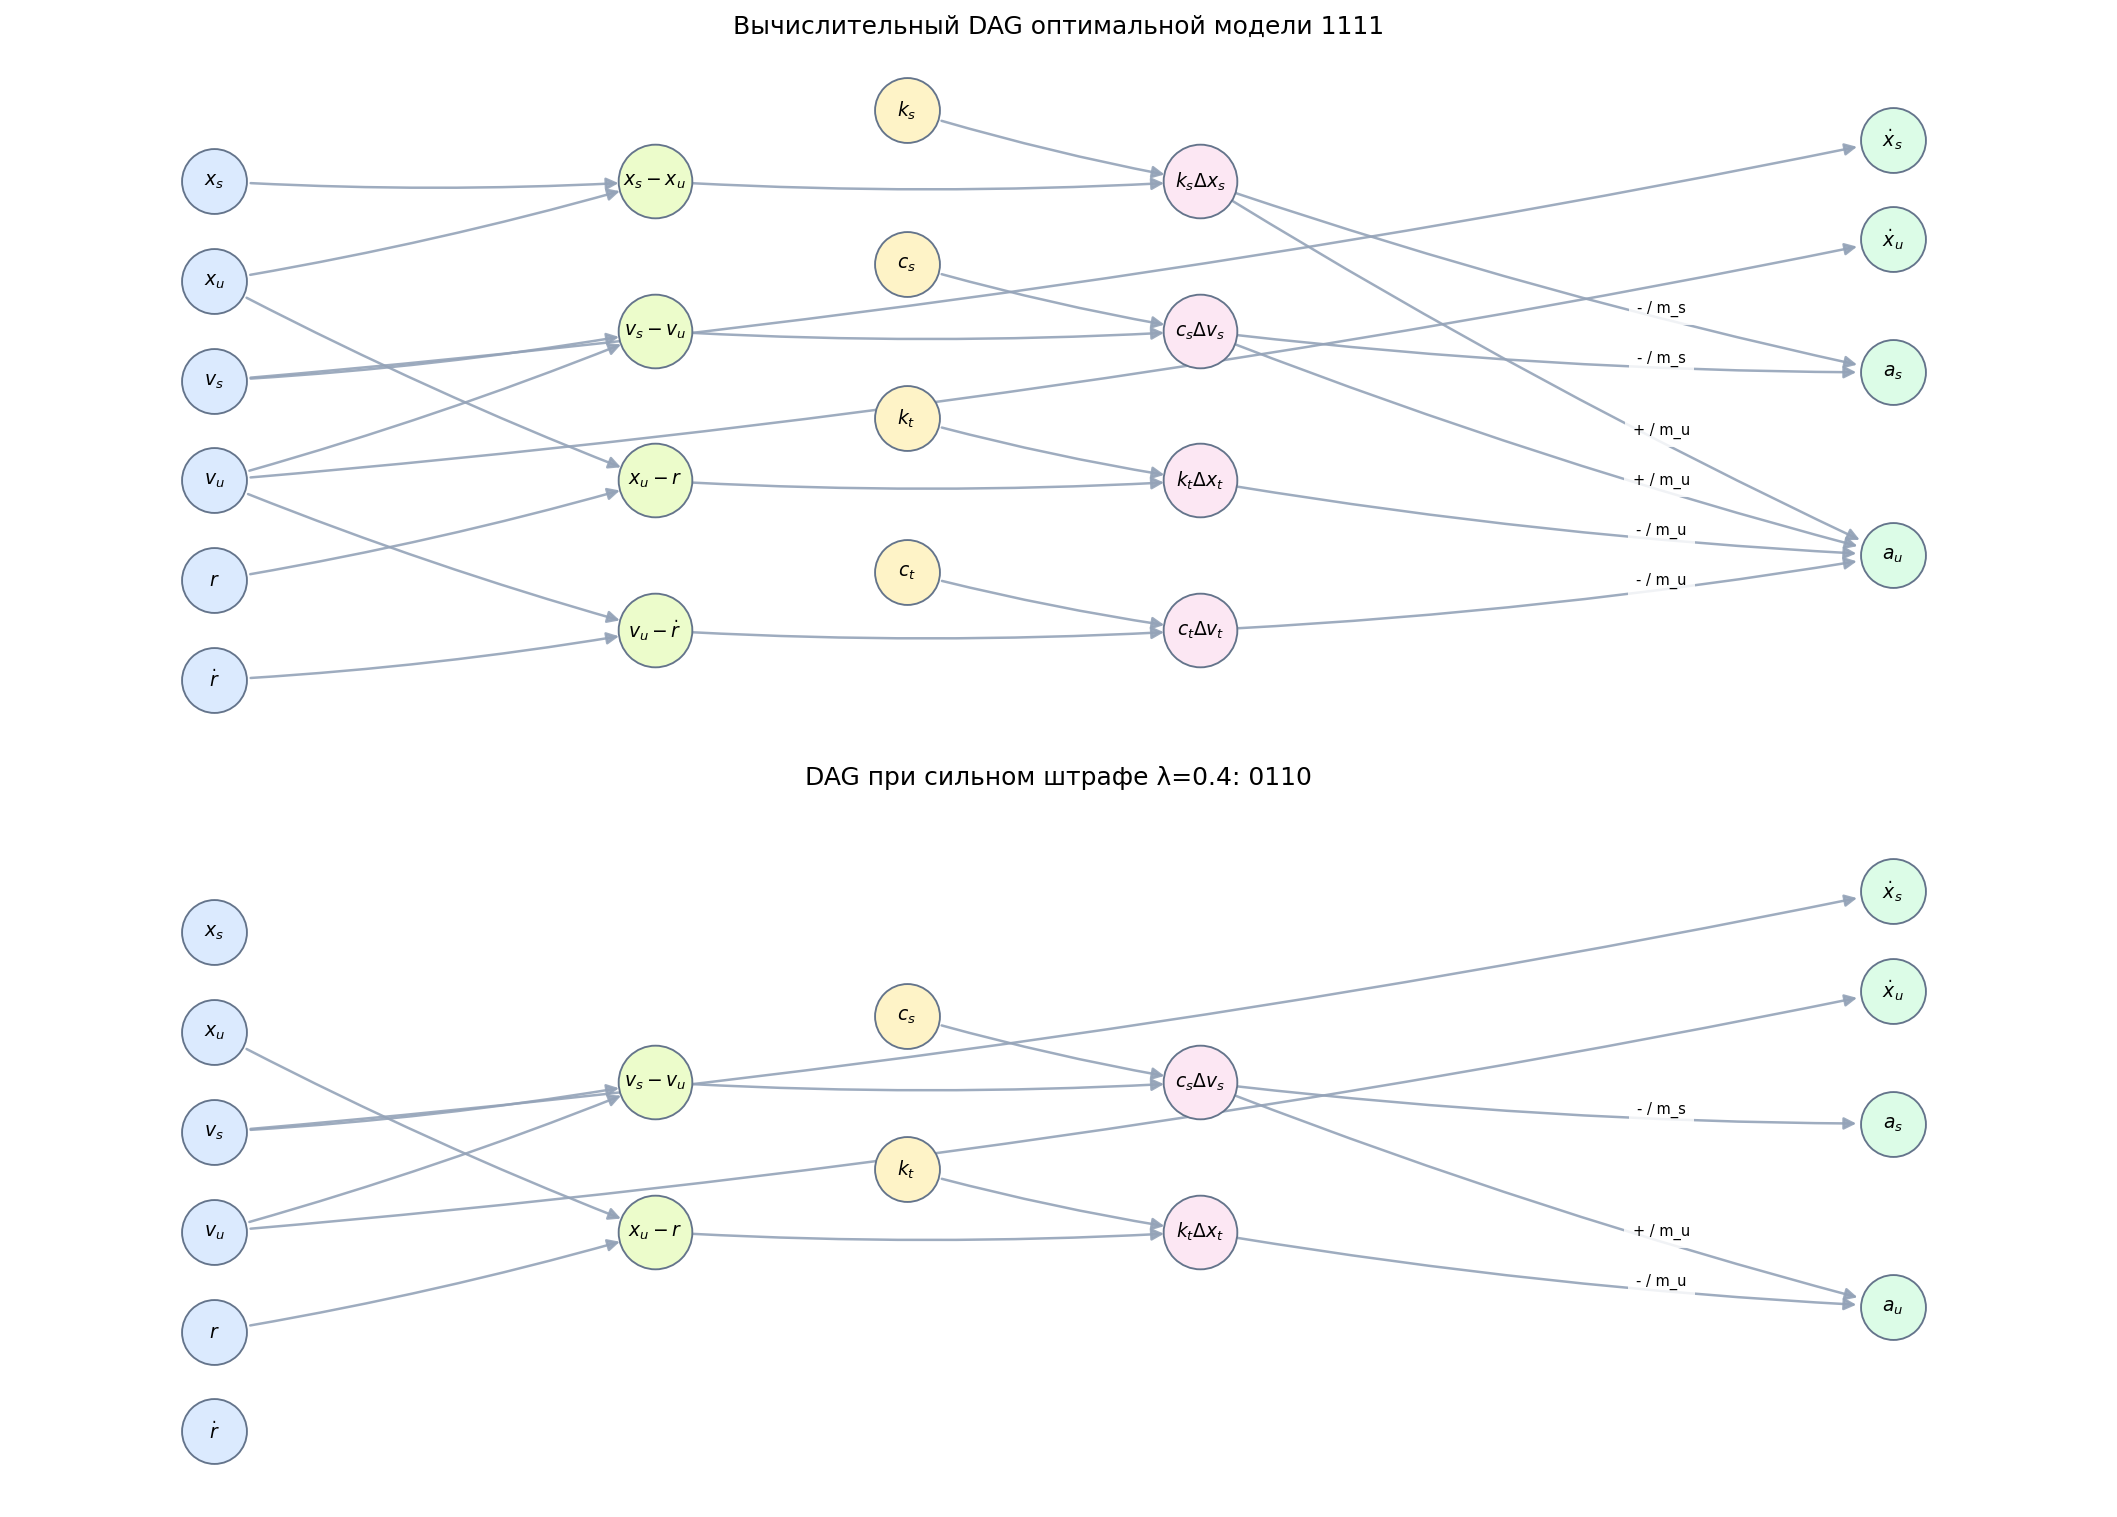

Сохранено: outputs/computation_graphs.png


In [ ]:
# Арифметическая схема ускорений / производных, а не только связи между наблюдениями.
strong_row = core.rescore_graphs(ranked, max(LAMBDA_GRID), INTERVENTION_WEIGHT).iloc[0]
fig, axs = plt.subplots(2, 1, figsize=(14, 10), constrained_layout=True)
core.draw_computation_graph(best_mask, ax=axs[0],
       title=f"Вычислительный DAG оптимальной модели {best['mask']}")
core.draw_computation_graph(core.mask_to_array(str(strong_row['mask'])), ax=axs[1],
       title=f"DAG при сильном штрафе λ={max(LAMBDA_GRID):g}: {strong_row['mask']}")
fig.savefig(OUT / "computation_graphs.png", dpi=180, bbox_inches="tight")
plt.show()
print("Сохранено:", OUT / "computation_graphs.png")


### 10. Измерения и аппроксимация предпочтительным графом

Временная интеграция найденной модели с **реальным** дорожным воздействием $r(t)$ (без дополнительного подбора параметров). Сравниваем измеренные и рассчитанные траектории кузова и колеса. Отклонения возможны из-за различий начальных условий и упрощений лабораторного стенда.

Временной RMSE: x_s=0.00463774 м; x_u=0.00467024 м


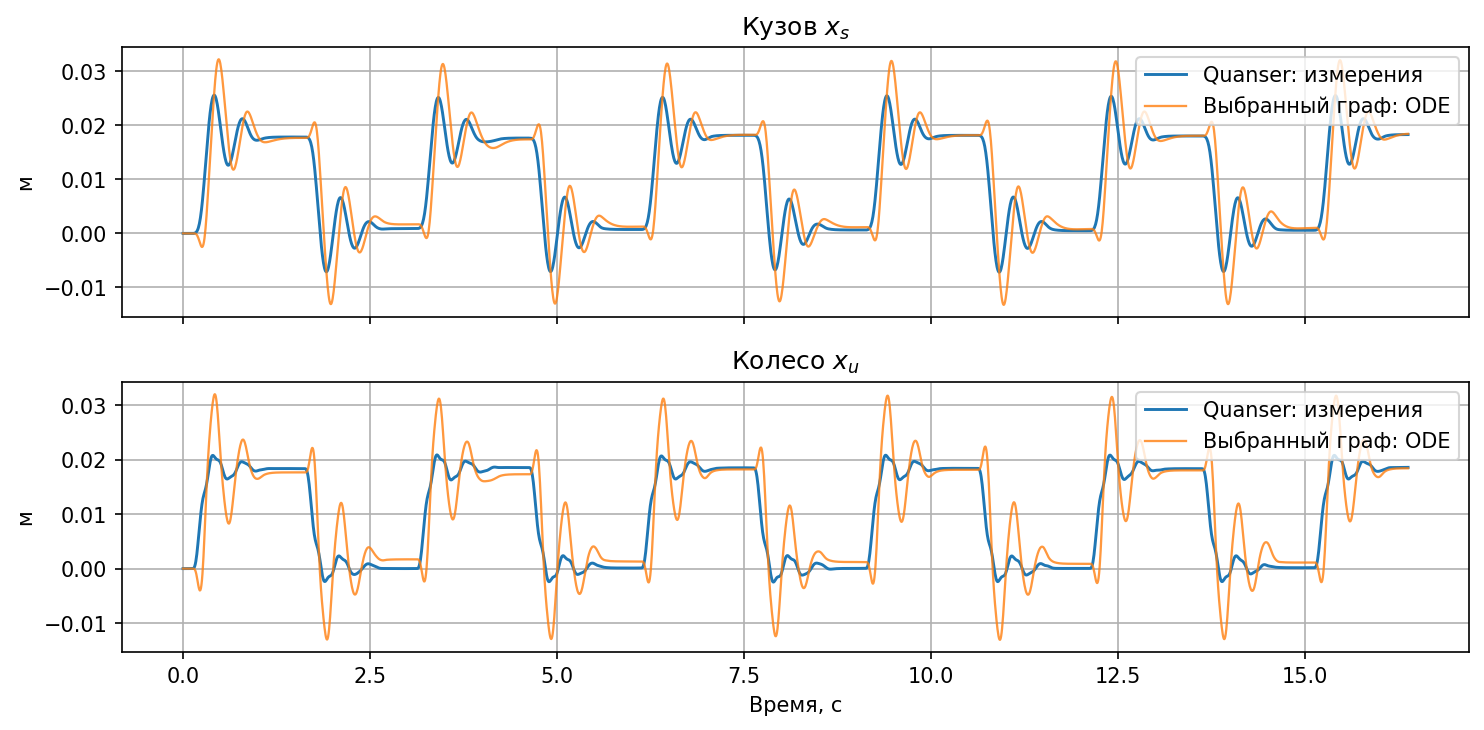

In [ ]:
predicted = core.simulate(exp, best_theta, best_mask)
real_positions = np.column_stack([exp.x_s, exp.x_u])
rmse_t = np.sqrt(np.mean((predicted[:,:2]-real_positions)**2, axis=0))
print(f"Временной RMSE: x_s={rmse_t[0]:.6g} м; x_u={rmse_t[1]:.6g} м")
fig, axs = plt.subplots(2,1,figsize=(10,5), sharex=True)
for j,(ax,name) in enumerate(zip(axs, ["Кузов $x_s$", "Колесо $x_u$"])):
    ax.plot(exp.t, real_positions[:,j],label="Quanser: измерения",lw=1.4)
    ax.plot(exp.t, predicted[:,j],label="Выбранный граф: ODE",lw=1.1,alpha=.8)
    ax.set(ylabel="м", title=name)
    ax.legend(loc="upper right")
axs[-1].set_xlabel("Время, с")
plt.tight_layout()
plt.show()

### 11. Результат и соответствие требованиям

После выполнения в `outputs/` сохраняются `smc_ks_results.csv` (распределения и KS), `candidate_graphs.csv` (16 оценённых графов), `generated_graph_samples.csv` (выборка потока) и `best_graph.graphml` (итоговый DAG). Таким образом, есть реализация и обоснование алгоритма, визуализация **последовательности** графов, сравнение реальных данных с ODE, решение об элементах структуры и критерий по точности/сложности/интервенциям.


**Источники:**
1. Salah, M. (2025). [Quanser Experimental Dataset](https://doi.org/10.7910/DVN/XGTWSJ), Harvard Dataverse. Реальные траектории и описание каналов, CC0.
2. [Sliding Mode Control for Active Suspension System with Data Acquisition Delay](https://doi.org/10.1155/2014/529293) (2014), табл. 1. Номинальные параметры подвески.
3. [Quanser Active Suspension](https://www.quanser.com/products/active-suspension/). Конструкция стенда и его назначение.
4. Dinh, L., Sohl-Dickstein, J., Bengio, S. (2017). [Density Estimation Using Real NVP](https://arxiv.org/abs/1605.08803). Архитектура normalizing flow.
5. Del Moral, P., Doucet, A., Jasra, A. (2006). [Sequential Monte Carlo Samplers](https://doi.org/10.1111/j.1467-9868.2006.00553.x). Основы SMC.
